# Antigen expression and co-detection


This notebook contains the manuscript-facing antigen-expression and
co-detection analyses. Positivity and co-detection are defined from raw
UMI counts. ALRA is used only to visualise ROR1 on the epithelial
embedding. Donors, rather than cells, are the unit of biological
replication.


## Setup

In [1]:
from itertools import combinations
from math import comb
import gc
import os
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

import scanpy as sc

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import binomtest, hypergeom, mannwhitneyu
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests

import rpy2.robjects as ro
import rpy2.rinterface_lib.callbacks as rcb

from rpy2.robjects import numpy2ri
from rpy2.robjects.conversion import localconverter
import logging


Error importing in API mode: ImportError("dlopen(/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: @rpath/R/lib/libR.dylib\n  Referenced from: <CBEF4F67-1D94-3EA0-88C4-F34EBE0600C2> /Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/bin/../lib/R/lib/libR.dylib' (no such file), '/Users/g

In [2]:
np.random.seed(0)

sc.settings.verbosity = 1

rcb.logger.setLevel(logging.ERROR)


In [3]:
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")

plt.rcParams.update({
    "font.size": 20,
    "axes.titlesize": 20,
    "axes.labelsize": 16,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
})


In [4]:
# genes and groupings used throughout
target_genes = ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]

antigen_pairs = [("ROR1", "EGFR"), ("EPCAM", "ERBB2")]

conditions = ["N", "ER+", "HER2+", "TN"]

tumour_conditions = ["TN", "HER2+", "ER+"]

# A cell is positive for a gene at this raw UMI count. Both pairs use the same threshold so their prevalences are on one scale. Only filtered matrices are available for GSE161529, so empty-droplet-based ambient-RNA estimation is not possible. The sweep below reports every panel at 1, 2 and 3 UMI.
primary_min_umi = 1

min_umi_sweep = [1, 2, 3]
# Donors need at least this many double-positive cells for programme-composition tests.
# This analysis threshold is checked explicitly at 1, 5, 10 and 20 cells below.
min_double_positive_cells = 5


In [5]:
def find_project(start=None):
    here = Path(start or Path.cwd()).resolve()
    for parent in [here, *here.parents]:
        if (parent / "Data").is_dir() and (parent / "metadata").is_dir():
            return parent
    raise FileNotFoundError("Set CAP_PROJECT to the project data directory")


def find_publication():
    here = Path.cwd().resolve()
    for parent in [here, *here.parents]:
        for candidate in (parent, parent / "publication_notebooks"):
            if (candidate / "scripts" / "publication_figure_state.py").is_file():
                if (candidate / "data" / "cancer_meta_programme_signatures.xlsx").is_file():
                    return candidate
    raise FileNotFoundError("Run from the publication_notebooks directory")


In [6]:
project = Path(os.environ.get("CAP_PROJECT") or find_project()).expanduser().resolve()

fig_dir = project / "Figures"

df_dir = project / "Dataframe_Saves"

save_dir = project / "Adata_Saves"

metadata_dir = project / "metadata"


In [7]:
for d in [fig_dir, df_dir, save_dir]:
    d.mkdir(parents=True, exist_ok=True)

sc.settings.figdir = fig_dir

# show paths relative to the project root, so no absolute path is ever printed
def rel(path):
    return Path(path).relative_to(project)


## Load

In [8]:
epi = sc.read_h5ad(save_dir / "epithelial_meta_programmes.h5ad")


In [9]:
display(epi)


AnnData object with n_obs × n_vars = 129111 × 27356
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'scVI_leiden', 'sample_short', 'celltypist_reference_label', 'celltypist_reference_confidence', 'cl_annotation', 'cnv_score', 'cnv_signal', 'tumour_derived', 'cnv_high', 'tumour_derived_cnv_high', 'g1_cell', 'tumour_derived_cnv_high_g1', 'specimen_origin', 'source_tumour_cluster', 'source_tumour_cluster_eligible', 'source_tumour_cluster_call', 'leiden_r0.5', 'leiden_r1', 'leiden_r1.2', 'leiden_r1.5', 'epi_leiden', 'epi_leiden_protected', 'epi_leiden_seed2', 'analysis_unit', 'MP_dominant_class', 'MP_programme_call', 'MP

In [10]:
epi


AnnData object with n_obs × n_vars = 129111 × 27356
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'scVI_leiden', 'sample_short', 'celltypist_reference_label', 'celltypist_reference_confidence', 'cl_annotation', 'cnv_score', 'cnv_signal', 'tumour_derived', 'cnv_high', 'tumour_derived_cnv_high', 'g1_cell', 'tumour_derived_cnv_high_g1', 'specimen_origin', 'source_tumour_cluster', 'source_tumour_cluster_eligible', 'source_tumour_cluster_call', 'leiden_r0.5', 'leiden_r1', 'leiden_r1.2', 'leiden_r1.5', 'epi_leiden', 'epi_leiden_protected', 'epi_leiden_seed2', 'analysis_unit', 'MP_dominant_class', 'MP_programme_call', 'MP

In [11]:
display(epi.obs["condition"].value_counts())


condition
ER+      59992
TN       26904
N        25682
HER2+    16533
Name: count, dtype: int64

In [12]:
for gene in target_genes:
    assert gene in epi.var_names, gene

for layer in ["counts", "lognorm"]:
    assert layer in epi.layers, layer


In [13]:
# raw positive-cell counts, re-checked after ALRA
baseline_positive = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}


In [14]:
display(baseline_positive)


{'ROR1': 1171, 'ROR2': 2674, 'EGFR': 12771, 'ERBB2': 36527, 'EPCAM': 61847}

In [15]:
def raw_counts(adata, gene):
    # raw UMI counts for one gene as a dense 1d array
    values = adata[:, gene].layers["counts"]
    return np.asarray(values.todense()).ravel() if sp.issparse(values) else np.asarray(values).ravel()


## ROR1 transcript detection



ROR1 is compared with genes of the same class and with positive controls, to
show that its sparsity is a property of the transcript rather than of the
dataset.

In [16]:
comparison_genes = {
    "ROR1": "target gene, surface receptor",
    "EPCAM": "epithelial marker",
    "MKI67": "proliferation marker",
    "ACTB": "housekeeping gene",
    "EGFR": "surface receptor",
    "ERBB2": "surface receptor",
}

comparison_genes = {g: d for g, d in comparison_genes.items() if g in epi.var_names}


In [17]:
detection = {g: raw_counts(epi, g) for g in comparison_genes}

rows = []


In [18]:
for gene, values in detection.items():
    rows.append({
        "gene": gene,
        "description": comparison_genes[gene],
        "pct_zero": 100 * (values == 0).mean(),
        "pct_detected": 100 * (values > 0).mean(),
        "pct_count1": 100 * (values == 1).mean(),
        "pct_count2plus": 100 * (values >= 2).mean(),
        "mean_count": values.mean(),
        "max_count": int(values.max()),
    })


In [19]:
detection_stats = pd.DataFrame(rows).set_index("gene")

display(detection_stats.round(3))

detection_stats.to_csv(df_dir / "ror1_detection_statistics.csv")


,description,pct_zero,pct_detected,pct_count1,pct_count2plus,mean_count,max_count
gene,,,,,,,
ROR1,"target gene, surface receptor",99.093,0.907,0.847,0.060,0.010,4
EPCAM,epithelial marker,52.098,47.902,17.868,30.034,1.806,66
MKI67,proliferation marker,93.526,6.474,3.403,3.071,0.146,60
ACTB,housekeeping gene,6.227,93.773,8.019,85.754,18.826,626
EGFR,surface receptor,90.109,9.891,7.104,2.788,0.152,76
ERBB2,surface receptor,71.709,28.291,13.869,14.422,1.840,147


In [20]:
ror1 = detection["ROR1"]


In [21]:
detection_palette = {
    "not detected": "#D9D9D9",
    "single UMI": "#56B4E9",
    "count >= 2": "#0072B2",
}


## ALRA imputation



Run per sample on the log-normalised expression of the integration gene set,
with the reconstruction rank chosen automatically by choose_k, the
singular-value search capped at 100 dimensions. ALRA output is used for visualisation only; every
threshold in this notebook is applied to raw counts.

In [22]:
# the deviance-ranked set plus the targets. This does not depend on whether the protected genes were added to the scVI feature set in 003a, so ALRA and the integration are selected independently.
alra_genes = epi.var_names[epi.var["highly_variable_deviance"]].tolist()
alra_genes = list(dict.fromkeys(alra_genes + target_genes))


In [23]:
for gene in target_genes:
    assert gene in alra_genes, gene


In [24]:
len(alra_genes)

ro.r('''
    suppressPackageStartupMessages({
        library(ALRA)
        library(rsvd)
    })

    options(mem.maxVSize = Inf)
    set.seed(0)
''')


In [25]:
gene_position = {gene: i for i, gene in enumerate(alra_genes)}

alra_values = {
    gene: np.full(epi.n_obs, np.nan, dtype=np.float32) for gene in target_genes
}

alra_ranks = []


In [26]:
def run_alra(matrix):
    matrix = matrix.toarray() if sp.issparse(matrix) else np.asarray(matrix)
    matrix = np.ascontiguousarray(matrix, dtype=np.float32)
    assert np.isfinite(matrix).all() and matrix.min() >= 0

    k_search = int(min(100, min(matrix.shape) - 1))
    noise_start = int(max(1, k_search - 20))
    with localconverter(ro.default_converter + numpy2ri.converter):
        ro.globalenv["X_sub"] = matrix

    ro.globalenv["k_search"] = ro.IntVector([k_search])
    ro.globalenv["noise_start"] = ro.IntVector([noise_start])
    ro.r("""
        k_choice <- try(choose_k(X_sub, K=k_search, noise_start=noise_start), silent=TRUE)
        if (inherits(k_choice, "try-error")) {
            k_use <- k_search
            k_auto <- FALSE
        } else {
            k_use <- k_choice$k
            k_auto <- TRUE
        }
        result <- alra(X_sub, k=k_use)
        X_imp <- as.matrix(result[[3]])
    """)

    imputed = np.asarray(ro.globalenv["X_imp"], dtype=np.float32)
    k_use = int(np.asarray(ro.globalenv["k_use"]).ravel()[0])
    k_auto = bool(np.asarray(ro.globalenv["k_auto"]).ravel()[0])
    ro.r("rm(X_sub, X_imp, result, k_choice); gc()")
    return imputed, k_search, k_use, k_auto


In [27]:
sample_values = epi.obs["sample"].astype(str).to_numpy()


In [28]:
for sample in np.unique(sample_values):
    mask = sample_values == sample
    n_cells = int(mask.sum())
    if n_cells < 50:
        continue

    matrix = epi[mask, alra_genes].layers["lognorm"]
    imputed, k_search, k_use, k_auto = run_alra(matrix)
    assert imputed.shape == (n_cells, len(alra_genes))

    for gene in target_genes:
        alra_values[gene][mask] = imputed[:, gene_position[gene]]

    alra_ranks.append({
        "sample": sample,
        "n_cells": n_cells,
        "k_search": k_search,
        "alra_k": k_use,
        "rank_chosen_automatically": k_auto,
    })
    del matrix, imputed
    gc.collect()


Read matrix with 3156 cells and 4002 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all except for 54 columns
0.16% of the values became negative in the scaling process and were set to zero
The matrix went from 28.60% nonzero to 64.26% nonzero
Read matrix with 3831 cells and 4002 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all except for 56 columns
0.14% of the values became negative in the scaling process and were set to zero
The matrix went from 31.30% nonzero to 68.20% nonzero
Read matrix with 2221 cells and 4002 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all except for 53 columns
0.38% of the values became negative in the scaling process and were set to zero
The matrix went from 34.15% nonzero to 64.31% nonzero
Read matrix with 815 cells and 4002 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all e

In [29]:
for gene in target_genes:
    epi.obs[f"{gene}_alra"] = alra_values[gene]


In [30]:
alra_ranks = pd.DataFrame(alra_ranks)

display(alra_ranks)

n_fallback = int((~alra_ranks["rank_chosen_automatically"]).sum())


,sample,n_cells,k_search,alra_k,rank_chosen_automatically
0,GSM4909253_N-PM0092-Total,3156,100,30,True
1,GSM4909254_N-PM0019-Total,3831,100,33,True
2,GSM4909257_N-PM0095-Total,2221,100,32,True
3,GSM4909261_N-PM0230-Total,815,100,26,True
4,GSM4909263_N-MH0064-Total,715,100,18,True
5,GSM4909265_N-PM0233-Total,2048,100,36,True
6,GSM4909266_N-MH0169-Total,724,100,24,True
7,GSM4909268_N-MH0023-Total,4071,100,35,True
8,GSM4909270_N-PM0342-Total,4361,100,35,True
9,GSM4909272_N-MH0021-Total,1232,100,15,True


In [31]:
if n_fallback:
    print(f"\\n{n_fallback} sample(s) fell back to k_search")


In [32]:
alra_ranks.to_csv(df_dir / "alra_rank_per_sample.csv", index=False)


In [33]:
epi.uns["alra"] = {
    "purpose": "visualisation and dropout reconstruction only",
    "input_layer": "lognorm",
    "run_per_sample": True,
    "rank_selection": "ALRA choose_k on the singular-value spacings",
    "k_search_cap": 100,
    "noise_gap": 20,
    "n_features": int(len(alra_genes)),
    "feature_set": "deviance-ranked genes plus target genes",
    "target_genes": target_genes,
    "n_samples_fallback": n_fallback,
}


In [34]:
# imputation must not have touched the raw counts
after = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}

assert after == baseline_positive, (baseline_positive, after)

rows = []


In [35]:
for gene in target_genes:

    raw = raw_counts(epi, gene)
    imputed = epi.obs[f"{gene}_alra"].to_numpy()

    rows.append({
        "gene": gene,
        "raw_detected_pct": 100 * (raw > 0).mean(),
        "alra_nonzero_pct": 100 * (imputed > 0).mean(),
        "median_alra_where_raw_zero": np.nanmedian(imputed[raw == 0]),
        "median_alra_where_raw_positive": np.nanmedian(imputed[raw > 0]),
    })


In [36]:
alra_summary = pd.DataFrame(rows)

display(alra_summary.round(3))

alra_summary.to_csv(df_dir / "alra_target_gene_summary.csv", index=False)


,gene,raw_detected_pct,alra_nonzero_pct,median_alra_where_raw_zero,median_alra_where_raw_positive
0,ROR1,0.907,9.291,0.000,0.694
1,ROR2,2.071,17.569,0.000,0.881
2,EGFR,9.891,30.605,0.000,0.991
3,ERBB2,28.291,77.901,0.767,1.562
4,EPCAM,47.902,87.394,1.024,1.655


In [37]:
# shared condition colours used throughout this notebook
condition_palette = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}

# Retain the existing name for supplementary plots.
condition_palette_supp = condition_palette

group_palette = {
    "TN tumour-derived epithelium": condition_palette["TN"],
    "ER+ tumour-derived epithelium": condition_palette["ER+"],
    "HER2+ tumour-derived epithelium": condition_palette["HER2+"],
    "Normal-tissue epithelium": condition_palette["N"],
}


## Antigen expression on the epithelial UMAP


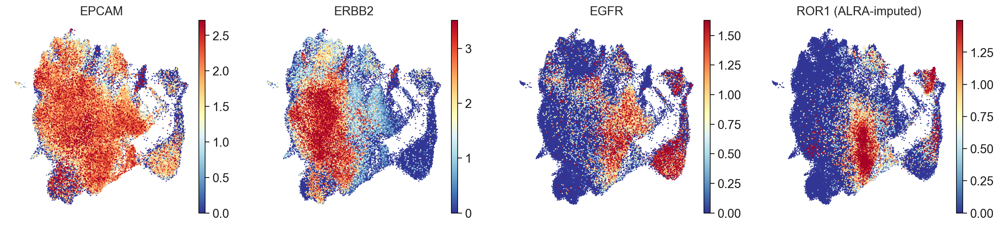

In [140]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import scanpy as sc

sc.set_figure_params(vector_friendly=True, dpi_save=300)  # dots -> one embedded raster per panel
mpl.rcParams["svg.fonttype"] = "none"   # or "path"
mpl.rcParams["font.family"] = "Arial"

sc.pl.umap(
    epi,
    layer="lognorm",
    use_raw=False,
    color=["EPCAM", "ERBB2", "EGFR", "ROR1_alra"],
    title=["EPCAM", "ERBB2", "EGFR", "ROR1 (ALRA-imputed)"],
    ncols=4,
    cmap="RdYlBu_r",
    vmax="p99",
    size=8,
    frameon=False,
    show=False,
)
plt.savefig(fig_dir / "antigen_expression_umap.svg", bbox_inches="tight")
plt.show()

In [141]:
condition_palette = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}

In [142]:
# draw N first so that the tumour conditions are not hidden underneath it
draw_order = ["N", "TN", "HER2+", "ER+"]
rank = {condition: i for i, condition in enumerate(draw_order)}

plot_idx = epi.obs["condition"].astype(str).map(rank).sort_values().index


/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


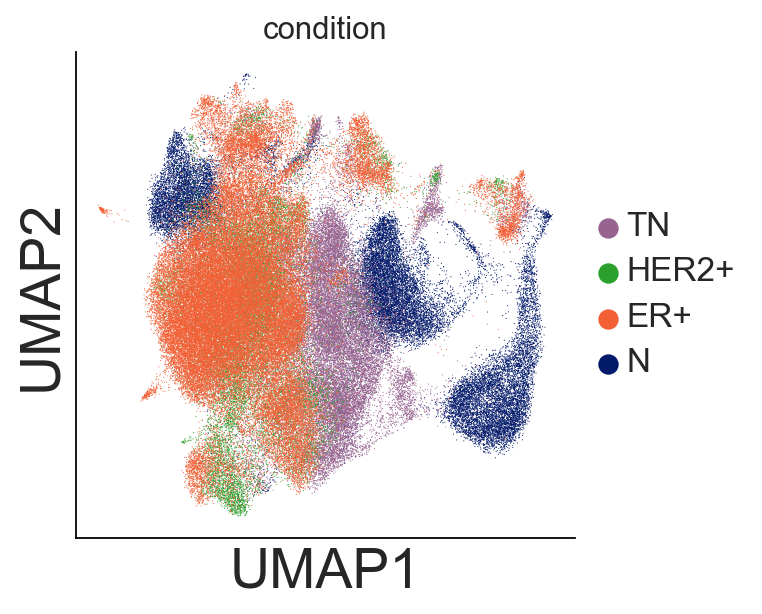

In [143]:
sc.pl.umap(
    epi[plot_idx],
    color="condition",
    palette=condition_palette,
    frameon=True,
    show=False,
)

ax = plt.gca()
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)


ax.tick_params(axis="both", labelsize=12)

legend = ax.get_legend()


if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)
    for handle in legend.legend_handles:
        handle.set_sizes([70])

sc.settings._vector_friendly = False   # fully vector, no embedded raster
plt.savefig(fig_dir / "epithelial_umap_condition.svg", bbox_inches="tight")
plt.show()

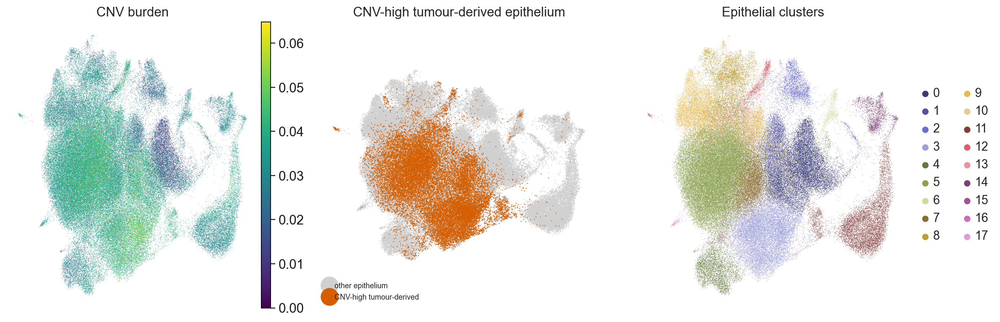

In [145]:
from matplotlib.lines import Line2D
umap = epi.obsm["X_umap"]
tumour_derived_cnv_high_plot = epi.obs["tumour_derived_cnv_high"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sc.pl.umap(epi,
           color="cnv_score", color_map="viridis", vmax="p99.9", frameon=False, title="CNV burden", ax=axes[0], show=False)

axes[1].scatter(umap[:, 0], umap[:, 1], s=1, color="#D0D0D0", linewidths=0, rasterized=True)
axes[1].scatter(umap[tumour_derived_cnv_high_plot, 0], umap[tumour_derived_cnv_high_plot, 1],
                s=1, color="#D55E00", linewidths=0, rasterized=True)

axes[1].set_title("CNV-high tumour-derived epithelium")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].set_aspect("equal", adjustable="datalim")


axes[1].set_frame_on(False)
axes[1].legend(
    handles=[
        Line2D([], [], marker="o", linestyle="none", color="#D0D0D0", label="other epithelium"),
        Line2D([], [], marker="o", linestyle="none", color="#D55E00", label="CNV-high tumour-derived"),
    ], frameon=False, loc="lower left", markerscale=3, fontsize=8)

sc.pl.umap(epi,
           color="epi_leiden", legend_loc="right margin", frameon=False, title="Epithelial clusters", ax=axes[2], show=False)

fig.tight_layout()
fig.savefig(fig_dir / "epithelial_umap_population_and_cnv.svg",
            dpi=300, bbox_inches="tight")
plt.show()

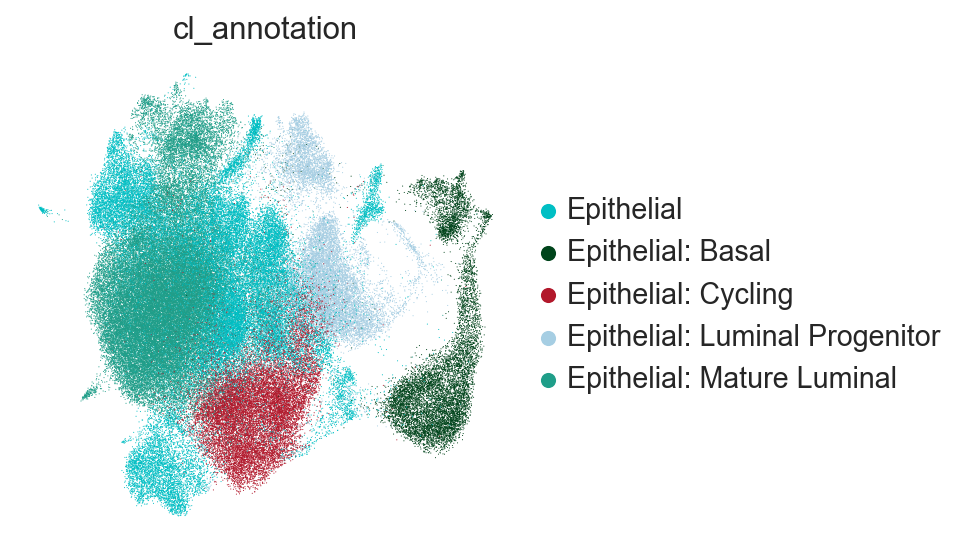

In [146]:
sc.pl.umap(epi, color="cl_annotation", frameon=False, show=False)

plt.savefig(fig_dir / "epithelial_umap_cl_annotation.svg", bbox_inches="tight")
plt.show()

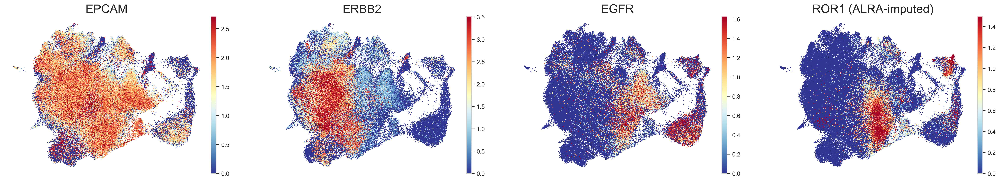

In [138]:
#EPCAM, ERBB2 and EGFR are shown as log-normalised expression. ROR1 is shown as ALRA-imputed expression because of its dropout, and the two scales are labelled separately rather than shared.

sc.pl.umap(
    epi,
    layer="lognorm",
    use_raw=False,
    color=["EPCAM", "ERBB2", "EGFR", "ROR1_alra"],
    title=["EPCAM", "ERBB2", "EGFR", "ROR1 (ALRA-imputed)"],
    ncols=4,
    cmap="RdYlBu_r",
    vmax="p99",
    size=8,
    frameon=False,
    show=False,
)

sc.settings._vector_friendly = False   # fully vector, no embedded raster
plt.savefig(fig_dir / "antigen_expression_umap.svg", bbox_inches="tight")


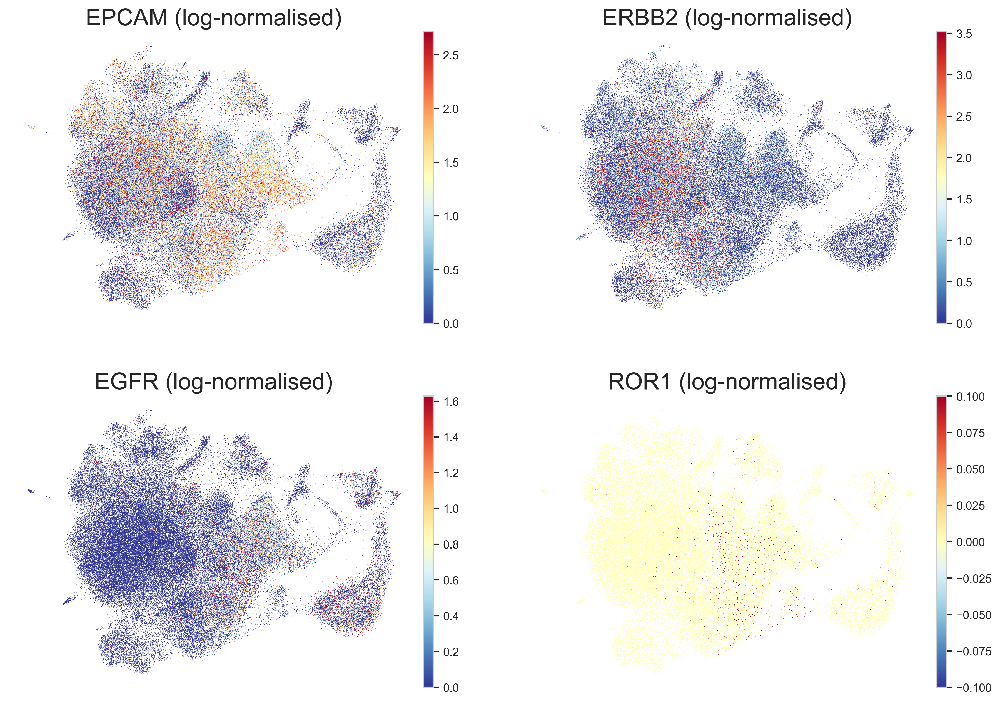

In [39]:
# the same four genes without imputation, for direct comparison
sc.pl.umap(
    epi,
    layer="lognorm",
    use_raw=False,
    color=["EPCAM", "ERBB2", "EGFR", "ROR1"],
    title=[f"{g} (log-normalised)" for g in ["EPCAM", "ERBB2", "EGFR", "ROR1"]],
    ncols=2,
    cmap="RdYlBu_r",
    vmax="p99",
    frameon=False,
    show=False,
)

plt.savefig(fig_dir / "antigen_expression_umap_raw.png", dpi=300, bbox_inches="tight")


plt.show()


Supplementary RNA detection and imputation diagnostics. ALRA values do not define antigen positivity or biological prevalence.

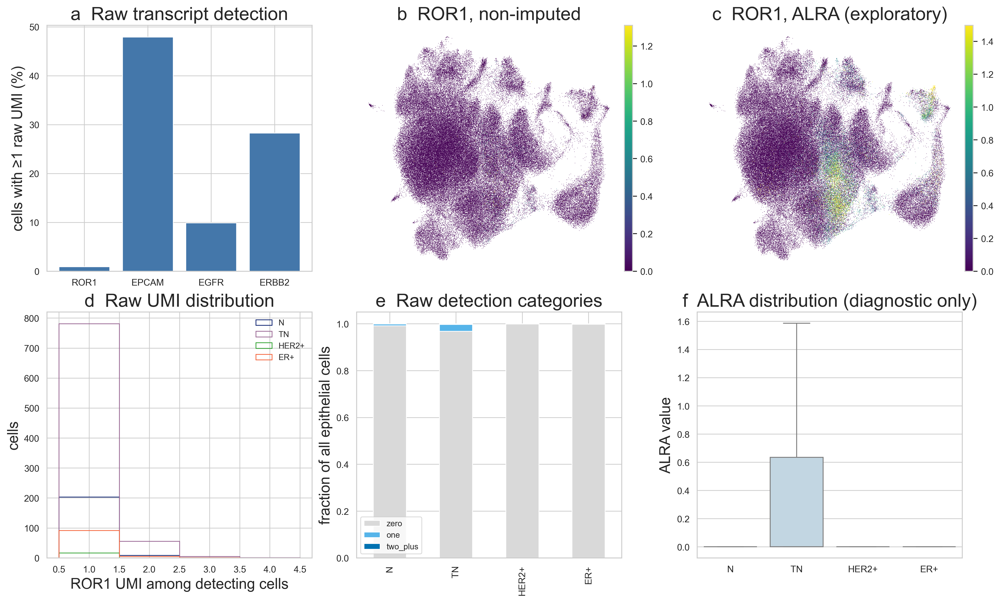

In [40]:
import sys
repository = find_publication()
if str(repository) not in sys.path:
    sys.path.insert(0, str(repository))

from scripts.publication_figure_state import save_supplementary_ror1

supplement_2_detection = save_supplementary_ror1(epi, fig_dir, output_tables=fig_dir)

## Antigen-pair co-expression

Positivity is called on raw counts, at one threshold shared by both pairs, so
that their prevalences are directly comparable.

In [41]:
def coexpression_group(adata, gene_a, gene_b, min_umi):
    # four mutually exclusive classes, called on raw UMI counts
    a = raw_counts(adata, gene_a) >= min_umi
    b = raw_counts(adata, gene_b) >= min_umi

    labels = np.full(adata.n_obs, "Double negative", dtype=object)
    labels[a & ~b] = f"{gene_a} only"
    labels[~a & b] = f"{gene_b} only"
    labels[a & b] = "Double positive"

    return pd.Categorical(
        labels,
        categories=["Double negative", f"{gene_a} only", f"{gene_b} only", "Double positive"],
        ordered=True,
    )


In [42]:
for gene_a, gene_b in antigen_pairs:

    column = f"{gene_a}_{gene_b}_group"
    epi.obs[column] = coexpression_group(epi, gene_a, gene_b, primary_min_umi)

    n = int((epi.obs[column] == "Double positive").sum())
    print(f"{column}: {n:,} double positive ({100 * n / epi.n_obs:.3f}%)")


ROR1_EGFR_group: 348 double positive (0.270%)
EPCAM_ERBB2_group: 24,387 double positive (18.888%)


In [43]:
epi.uns["coexpression"] = {
    "expression": "raw UMI counts",
    "min_umi": primary_min_umi,
    "pairs": ["-".join(pair) for pair in antigen_pairs],
    "note": "ALRA values are not used for thresholding",
}

# both pairs at every threshold, whole epithelial compartment and per condition
rows = []


In [44]:
# the loop variable is deliberately not called min_umi: rebinding the primary threshold here would silently change every analysis below
for threshold_umi in min_umi_sweep:
    for gene_a, gene_b in antigen_pairs:

        groups = coexpression_group(epi, gene_a, gene_b, threshold_umi)
        double_positive = np.asarray(groups == "Double positive")

        rows.append({
            "pair": f"{gene_a}-{gene_b}",
            "min_umi": threshold_umi,
            "condition": "all",
            "n_cells": epi.n_obs,
            "n_double_positive": int(double_positive.sum()),
            "pct_double_positive": 100 * double_positive.mean(),
        })

        for condition in conditions:

            mask = (epi.obs["condition"].astype(str) == condition).to_numpy()

            rows.append({
                "pair": f"{gene_a}-{gene_b}",
                "min_umi": threshold_umi,
                "condition": condition,
                "n_cells": int(mask.sum()),
                "n_double_positive": int(double_positive[mask].sum()),
                "pct_double_positive": 100 * double_positive[mask].mean(),
            })


In [45]:
threshold_sweep = pd.DataFrame(rows)

display(threshold_sweep .pivot_table(index=["pair", "condition"], columns="min_umi", values="pct_double_positive") .round(3))

threshold_sweep.to_csv(df_dir / "coexpression_threshold_sweep.csv", index=False)


min_umi                     1       2       3
pair        condition                        
EPCAM-ERBB2 ER+        12.075   3.554   1.332
            HER2+      59.233  42.164  31.930
            N          14.185   3.734   1.075
            TN         13.779   2.542   0.565
            all        18.888   8.323   5.039
ROR1-EGFR   ER+         0.032   0.000   0.000
            HER2+       0.012   0.000   0.000
            N           0.440   0.016   0.004
            TN          0.795   0.015   0.000
            all         0.270   0.006   0.001

In [46]:
condition_values = epi.obs["condition"].astype(str).to_numpy()
tumour_derived_only = epi.obs["tumour_derived"].astype(bool).to_numpy()
normal_tissue_only = ~tumour_derived_only
tumour_derived_cnv_high_only = epi.obs["tumour_derived_cnv_high"].astype(bool).to_numpy()
g1_only = epi.obs["g1_cell"].astype(bool).to_numpy()
tumour_derived_cnv_high_g1_only = tumour_derived_cnv_high_only & g1_only

rows = []


In [47]:
for gene_a, gene_b in antigen_pairs:
    double_positive = np.asarray(
        coexpression_group(epi, gene_a, gene_b, primary_min_umi) == "Double positive"
    )

    scopes = [
        ("all_epithelial", np.ones(epi.n_obs, bool)),
        ("tumour_derived", tumour_derived_only),
        ("tumour_derived_cnv_high", tumour_derived_cnv_high_only),
        ("tumour_derived_cnv_high_g1", tumour_derived_cnv_high_g1_only),
    ]
    for scope, scope_mask in scopes:
        for condition in conditions:
            mask = scope_mask & (condition_values == condition)

            if mask.sum() == 0:
                continue

            rows.append({
                "pair": f"{gene_a}-{gene_b}",
                "scope": scope,
                "condition": condition,
                "n_cells": int(mask.sum()),
                "n_double_positive": int(double_positive[mask].sum()),
                "pct_double_positive": 100 * double_positive[mask].mean(),
            })


In [48]:
coexpression_by_scope = pd.DataFrame(rows)

display(
    coexpression_by_scope.pivot_table(
        index=["pair", "condition"],
        columns="scope",
        values="pct_double_positive",
    ).round(3)
)


scope                  all_epithelial  tumour_derived  \
pair        condition                                   
EPCAM-ERBB2 ER+                12.075          12.075   
            HER2+              59.233          59.233   
            N                  14.185             NaN   
            TN                 13.779          13.779   
ROR1-EGFR   ER+                 0.032           0.032   
            HER2+               0.012           0.012   
            N                   0.440             NaN   
            TN                  0.795           0.795   

scope                  tumour_derived_cnv_high  tumour_derived_cnv_high_g1  
pair        condition                                                       
EPCAM-ERBB2 ER+                         22.543                      24.232  
            HER2+                       57.226                      58.396  
            N                              NaN                         NaN  
            TN                          12.689                      13.967  
ROR1-EGFR   ER+                          0.032                       0.053  
            HER2+                        0.000                       0.000  
            N                              NaN                         NaN  
            TN                           1.100                       0.627

In [49]:
coexpression_by_scope.to_csv(
    df_dir / "coexpression_population_sensitivity.csv", index=False
)


In [50]:
cycle_scope_summary = coexpression_by_scope[
    coexpression_by_scope["scope"].isin(
        ["tumour_derived_cnv_high", "tumour_derived_cnv_high_g1"]
    )
].copy()
cycle_scope_summary.to_csv(
    df_dir / "coexpression_cnv_high_g1_sensitivity.csv", index=False
)
display(cycle_scope_summary.round(4))


,pair,scope,condition,n_cells,n_double_positive,pct_double_positive
7,ROR1-EGFR,tumour_derived_cnv_high,ER+,9453,3,0.0317
8,ROR1-EGFR,tumour_derived_cnv_high,HER2+,3598,0,0.0000
9,ROR1-EGFR,tumour_derived_cnv_high,TN,9276,102,1.0996
10,ROR1-EGFR,tumour_derived_cnv_high_g1,ER+,5629,3,0.0533
11,ROR1-EGFR,tumour_derived_cnv_high_g1,HER2+,2519,0,0.0000
12,ROR1-EGFR,tumour_derived_cnv_high_g1,TN,2871,18,0.6270
20,EPCAM-ERBB2,tumour_derived_cnv_high,ER+,9453,2131,22.5431
21,EPCAM-ERBB2,tumour_derived_cnv_high,HER2+,3598,2059,57.2262
22,EPCAM-ERBB2,tumour_derived_cnv_high,TN,9276,1177,12.6887
23,EPCAM-ERBB2,tumour_derived_cnv_high_g1,ER+,5629,1364,24.2317


In [51]:
# co-detection against the rate expected if the two transcripts were independent
rows = []


In [52]:
for gene_a, gene_b in antigen_pairs:

    a = raw_counts(epi, gene_a) >= primary_min_umi
    b = raw_counts(epi, gene_b) >= primary_min_umi

    for condition in conditions:

        mask = (epi.obs["condition"].astype(str) == condition).to_numpy()

        p_a = a[mask].mean()
        p_b = b[mask].mean()
        observed = (a & b)[mask].mean()
        expected = p_a * p_b

        rows.append({
            "pair": f"{gene_a}-{gene_b}",
            "condition": condition,
            "pct_a": 100 * p_a,
            "pct_b": 100 * p_b,
            "pct_observed": 100 * observed,
            "pct_expected": 100 * expected,
            "observed_over_expected": observed / expected if expected > 0 else np.nan,
        })


In [53]:
independence = pd.DataFrame(rows)

display(independence.round(3))

independence.to_csv(df_dir / "coexpression_observed_over_expected.csv", index=False)


,pair,condition,pct_a,pct_b,pct_observed,pct_expected,observed_over_expected
0,ROR1-EGFR,N,0.829,25.617,0.440,0.212,2.071
1,ROR1-EGFR,ER+,0.163,2.335,0.032,0.004,8.302
2,ROR1-EGFR,HER2+,0.103,3.036,0.012,0.003,3.875
3,ROR1-EGFR,TN,3.133,15.942,0.795,0.500,1.592
4,EPCAM-ERBB2,N,59.073,16.175,14.185,9.555,1.485
5,EPCAM-ERBB2,ER+,32.903,22.943,12.075,7.549,1.600
6,EPCAM-ERBB2,HER2+,63.364,82.707,59.233,52.407,1.130
7,EPCAM-ERBB2,TN,61.184,18.343,13.779,11.223,1.228


## Tumour-derived versus normal-tissue co-detection



Everything below uses raw UMI counts. ALRA is used for visualisation only.

The unit of replication is the donor, not the cell. Pooled prevalence and donor-level
prevalence are reported separately because they answer different questions and can
disagree when donors differ greatly in size.

In [54]:
min_donor_cells = 100

window_group = np.where(
    normal_tissue_only,
    "Normal-tissue epithelium",
    epi.obs["condition"].astype(str) + " tumour-derived epithelium",
)

ror1_positive = raw_counts(epi, "ROR1") >= primary_min_umi
egfr_positive = raw_counts(epi, "EGFR") >= primary_min_umi

assert "patient" in epi.obs.columns, "patient metadata is required for donor-level inference"


In [55]:
assert epi.obs["patient"].notna().all(), "patient metadata contains missing values"

window = pd.DataFrame({
    "group": window_group,
    "patient": epi.obs["patient"].astype(str).to_numpy(),
    "sample": epi.obs["sample"].astype(str).to_numpy(),
    "ror1": ror1_positive,
    "egfr": egfr_positive,
    "double_positive": ror1_positive & egfr_positive,
})

window = window[window["group"] != "excluded"]


In [56]:
by_donor = (
    window.groupby(["group", "patient"], observed=True)
    .agg(n_cells=("double_positive", "size"),
         n_ror1=("ror1", "sum"),
         n_egfr=("egfr", "sum"),
         n_double_positive=("double_positive", "sum"))
    .reset_index()
)

by_donor["prevalence"] = by_donor["n_double_positive"] / by_donor["n_cells"] * 100


In [57]:
def summarise_window(frame):
    """pooled and donor-level statistics side by side, never merged into one column"""
    rows = []

    for group, g in frame.groupby("group", observed=True):

        rows.append({
            "group": group,
            "donors": len(g),
            "total_cells": int(g["n_cells"].sum()),
            "total_double_positive": int(g["n_double_positive"].sum()),
            "pooled_pct": g["n_double_positive"].sum() / g["n_cells"].sum() * 100,
            "donor_mean_pct": g["prevalence"].mean(),
            "donor_median_pct": g["prevalence"].median(),
            "donor_q1_pct": g["prevalence"].quantile(0.25),
            "donor_q3_pct": g["prevalence"].quantile(0.75),
            "donors_with_signal": int((g["n_double_positive"] > 0).sum()),
        })

    return pd.DataFrame(rows)


In [58]:
eligible_donors = by_donor[by_donor["n_cells"] >= min_donor_cells]

origin_comparison = summarise_window(eligible_donors)
origin_comparison.to_csv(df_dir / "coexpression_tumour_derived_vs_normal.csv", index=False)

display(origin_comparison.round(4))

# the eligibility rule should not decide the answer
rows = []


,group,donors,total_cells,total_double_positive,pooled_pct,donor_mean_pct,donor_median_pct,donor_q1_pct,donor_q3_pct,donors_with_signal
0,ER+ tumour-derived epithelium,8,59992,19,0.0317,0.0424,0.0162,0.0000,0.0558,5
1,HER2+ tumour-derived epithelium,1,16533,2,0.0121,0.0121,0.0121,0.0121,0.0121,1
2,Normal-tissue epithelium,12,25682,113,0.4400,0.4251,0.3411,0.1781,0.5043,10
3,TN tumour-derived epithelium,3,26904,214,0.7954,0.5340,0.5959,0.2979,0.8009,2


In [59]:
for rule in [0, 50, 100]:

    summary = summarise_window(by_donor[by_donor["n_cells"] >= rule]).set_index("group")

    tn = summary.loc["TN tumour-derived epithelium"]
    normal = summary.loc["Normal-tissue epithelium"]

    rows.append({
        "min_donor_cells": rule,
        "tn_donors": int(tn["donors"]),
        "tn_pooled_pct": tn["pooled_pct"],
        "tn_donor_mean_pct": tn["donor_mean_pct"],
        "normal_pooled_pct": normal["pooled_pct"],
        "pooled_ratio": tn["pooled_pct"] / normal["pooled_pct"],
    })


In [60]:
eligibility_sensitivity = pd.DataFrame(rows)
eligibility_sensitivity.to_csv(df_dir / "coexpression_eligibility_sensitivity.csv", index=False)

display(eligibility_sensitivity.round(4))


,min_donor_cells,tn_donors,tn_pooled_pct,tn_donor_mean_pct,normal_pooled_pct,pooled_ratio
0,0,3,0.7954,0.534,0.44,1.8078
1,50,3,0.7954,0.534,0.44,1.8078
2,100,3,0.7954,0.534,0.44,1.8078


### CNV-high and G1 sensitivity

The CNV-high analysis is repeated after restricting both tumour-derived and
normal reference cells to G1. This tests whether cycling transcription drives
the CNV-based enrichment without treating G1 as evidence against malignancy.


In [61]:
def scoped_donor_prevalence(scope, tumour_mask, normal_mask):
    included = tumour_mask | normal_mask
    frame = pd.DataFrame({
        "scope": scope,
        "condition": np.where(normal_mask, "N", condition_values),
        "patient": epi.obs["patient"].astype(str).to_numpy(),
        "double_positive": ror1_positive & egfr_positive,
    })
    frame = frame[included]
    donor = (
        frame.groupby(["scope", "condition", "patient"], observed=True)
        .agg(
            n_cells=("double_positive", "size"),
            n_double_positive=("double_positive", "sum"),
        )
        .reset_index()
    )
    donor["prevalence"] = (
        100 * donor["n_double_positive"] / donor["n_cells"]
    )
    return donor


In [62]:
cycle_sensitivity_donors = pd.concat([
    scoped_donor_prevalence(
        "tumour_derived", tumour_derived_only, normal_tissue_only
    ),
    scoped_donor_prevalence(
        "tumour_derived_cnv_high", tumour_derived_cnv_high_only, normal_tissue_only
    ),
    scoped_donor_prevalence(
        "tumour_derived_cnv_high_g1", tumour_derived_cnv_high_g1_only,
        normal_tissue_only & g1_only,
    ),
], ignore_index=True)
cycle_sensitivity_donors = cycle_sensitivity_donors[
    cycle_sensitivity_donors["n_cells"] >= min_donor_cells
].copy()
cycle_sensitivity_donors.to_csv(
    df_dir / "coexpression_cnv_high_g1_by_donor.csv", index=False
)


In [63]:
cycle_sensitivity_summary = (
    cycle_sensitivity_donors
    .groupby(["scope", "condition"], observed=True)
    .agg(
        donors=("patient", "nunique"),
        total_cells=("n_cells", "sum"),
        total_double_positive=("n_double_positive", "sum"),
        donor_mean_pct=("prevalence", "mean"),
        donor_median_pct=("prevalence", "median"),
    )
    .reset_index()
)
cycle_sensitivity_summary["pooled_pct"] = (
    100 * cycle_sensitivity_summary["total_double_positive"]
    / cycle_sensitivity_summary["total_cells"]
)
cycle_sensitivity_summary.to_csv(
    df_dir / "coexpression_cnv_high_g1_summary.csv", index=False
)
display(cycle_sensitivity_summary.round(4))


,scope,condition,donors,total_cells,total_double_positive,donor_mean_pct,donor_median_pct,pooled_pct
0,tumour_derived,ER+,8,59992,19,0.0424,0.0162,0.0317
1,tumour_derived,HER2+,1,16533,2,0.0121,0.0121,0.0121
2,tumour_derived,N,12,25682,113,0.4251,0.3411,0.4400
3,tumour_derived,TN,3,26904,214,0.5340,0.5959,0.7954
4,tumour_derived_cnv_high,ER+,8,9453,3,0.0084,0.0000,0.0317
5,tumour_derived_cnv_high,HER2+,1,3598,0,0.0000,0.0000,0.0000
6,tumour_derived_cnv_high,N,12,25682,113,0.4251,0.3411,0.4400
7,tumour_derived_cnv_high,TN,2,9227,102,1.2989,1.2989,1.1055
8,tumour_derived_cnv_high_g1,ER+,6,5474,3,0.0182,0.0000,0.0548
9,tumour_derived_cnv_high_g1,HER2+,1,2519,0,0.0000,0.0000,0.0000


## Exact conditional ROR1–EGFR overlap



Observed double-positive prevalence does not establish that the two transcripts
co-occur more often than expected from their separate detection rates. This test
conditions on the observed ROR1-positive and EGFR-positive margins within each
patient, technical sample and library-depth bin. Under conditional independence,
the overlap in each stratum is hypergeometric. Convolving those stratum-specific
distributions gives an exact upper-tail probability without Monte-Carlo error.

The main analysis uses TN tumour-derived epithelium with at least one raw UMI per
gene with ten within-sample depth bins. Other tumour groups, normal epithelium,
the two-UMI threshold and alternative bin counts are sensitivity analyses with
Holm adjustment. The pooled conditional test is cell-level evidence within this
cohort; donor-level direction and an exact sign test are reported separately for
generalisation across patients.


In [64]:
overlap_depth_bins = [5, 10, 20]
overlap_primary_bins = 10
overlap_thresholds = [1, 2]
overlap_group_order = [
    "TN tumour-derived epithelium",
    "ER+ tumour-derived epithelium",
    "HER2+ tumour-derived epithelium",
    "Normal-tissue epithelium",
]


In [65]:
overlap_library_size = np.rint(
    epi.obs["total_counts"].to_numpy(float)
).astype(np.int64)

overlap_base = pd.DataFrame({
    "group": window_group,
    "patient": epi.obs["patient"].astype(str).to_numpy(),
    "sample": epi.obs["sample"].astype(str).to_numpy(),
    "total_counts": overlap_library_size,
    "ror1_count": raw_counts(epi, "ROR1").astype(np.int64),
    "egfr_count": raw_counts(epi, "EGFR").astype(np.int64),
})


In [66]:
overlap_base = overlap_base[overlap_base["group"] != "excluded"].copy()

# Match the donor eligibility rule used by the prevalence analysis.
eligible_overlap_units = set(
    eligible_donors[["group", "patient"]].itertuples(index=False, name=None)
)
overlap_base = overlap_base[
    pd.MultiIndex.from_frame(overlap_base[["group", "patient"]]).isin(
        eligible_overlap_units
    )
].copy()


In [67]:
assert overlap_base["total_counts"].gt(0).all()
assert set(overlap_base["group"]).issubset(overlap_group_order)


In [68]:
def add_within_sample_depth_bins(frame, n_bins):
    """Assign deterministic quantile bins without mixing technical samples."""
    frame = frame.copy()

    def assign_bins(values):
        # Equal library sizes remain exchangeable and are never split arbitrarily.
        requested = min(n_bins, len(values))
        bins = pd.qcut(
            values,
            q=requested,
            labels=False,
            duplicates="drop",
        )
        if bins.isna().all():
            return pd.Series(0, index=values.index, dtype=int)
        return bins.fillna(0).astype(int)

    frame["depth_bin"] = (
        frame.groupby(["patient", "sample"], observed=True)["total_counts"]
        .transform(assign_bins)
    )
    return frame


In [69]:
def stratum_overlap_distribution(n_cells, n_ror1, n_egfr):
    lower = max(0, n_ror1 + n_egfr - n_cells)
    upper = min(n_ror1, n_egfr)
    support = np.arange(lower, upper + 1)
    distribution = np.zeros(upper + 1, dtype=float)
    distribution[lower:upper + 1] = hypergeom.pmf(
        support, n_cells, n_ror1, n_egfr
    )
    return distribution


In [70]:
def exact_stratified_overlap(frame):
    """Exact overlap test across patient, sample and depth strata."""
    distribution = np.array([1.0])
    observed = 0
    expected = 0.0
    variance = 0.0
    n_strata = 0

    groups = frame.groupby(
        ["patient", "sample", "depth_bin"], observed=True, sort=False
    )
    for _, stratum in groups:
        n_cells = len(stratum)
        n_ror1 = int(stratum["ror1_positive"].sum())
        n_egfr = int(stratum["egfr_positive"].sum())
        observed += int(stratum["double_positive"].sum())
        expected += n_ror1 * n_egfr / n_cells
        if n_cells > 1:
            variance += n_egfr * (n_ror1 / n_cells) * (1 - n_ror1 / n_cells) * (
                (n_cells - n_egfr) / (n_cells - 1)
            )
        distribution = np.convolve(
            distribution,
            stratum_overlap_distribution(n_cells, n_ror1, n_egfr),
        )
        distribution /= distribution.sum()
        n_strata += 1

    p_upper = float(distribution[observed:].sum()) if observed < len(distribution) else 0.0
    return {
        "n_cells": int(len(frame)), "n_strata": n_strata,
        "n_ror1": int(frame["ror1_positive"].sum()),
        "n_egfr": int(frame["egfr_positive"].sum()),
        "observed_double_positive": observed,
        "expected_double_positive": expected,
        "variance_under_independence": variance,
        "observed_over_expected": observed / expected if expected > 0 else np.nan,
        "p_upper_exact": p_upper,
        "p_underflow": p_upper == 0.0,
    }


In [71]:
cohort_rows = []
donor_rows = []


In [72]:
for threshold_umi in overlap_thresholds:
    for n_bins in overlap_depth_bins:
        analysed = overlap_base.copy()
        analysed["ror1_positive"] = analysed["ror1_count"] >= threshold_umi
        analysed["egfr_positive"] = analysed["egfr_count"] >= threshold_umi
        analysed["double_positive"] = (
            analysed["ror1_positive"] & analysed["egfr_positive"]
        )
        analysed = add_within_sample_depth_bins(analysed, n_bins)

        for group in overlap_group_order:
            group_frame = analysed[analysed["group"] == group]
            if group_frame.empty:
                continue

            cohort_result = exact_stratified_overlap(group_frame)
            cohort_result.update({
                "group": group,
                "min_umi": threshold_umi,
                "depth_bins_requested": n_bins,
                "n_donors": int(group_frame["patient"].nunique()),
                "primary_test": bool(
                    group == "TN tumour-derived epithelium"
                    and threshold_umi == primary_min_umi
                    and n_bins == overlap_primary_bins
                ),
            })
            cohort_rows.append(cohort_result)

            for patient, donor_frame in group_frame.groupby("patient", observed=True):
                donor_result = exact_stratified_overlap(donor_frame)
                donor_result.update({
                    "group": group,
                    "patient": str(patient),
                    "min_umi": threshold_umi,
                    "depth_bins_requested": n_bins,
                })
                donor_rows.append(donor_result)


In [73]:
overlap_cohort = pd.DataFrame(cohort_rows)
overlap_by_donor = pd.DataFrame(donor_rows)

# The main 1-UMI/10-bin result is reported separately. Holm adjustment covers the sensitivity family.
overlap_cohort["p_holm_all_tests"] = multipletests(
    overlap_cohort["p_upper_exact"], method="holm"
)[1]

overlap_cohort.to_csv(
    df_dir / "ror1_egfr_exact_conditional_overlap_cohort.csv", index=False
)


In [74]:
overlap_by_donor.to_csv(
    df_dir / "ror1_egfr_exact_conditional_overlap_by_donor.csv", index=False
)

# Donor-level direction: ties do not enter the sign-test denominator.
direction_rows = []


In [75]:
for keys, donors in overlap_by_donor.groupby(
    ["group", "min_umi", "depth_bins_requested"], observed=True
):
    group, threshold_umi, n_bins = keys
    informative = donors[donors["expected_double_positive"] > 0].copy()
    delta = (
        informative["observed_double_positive"]
        - informative["expected_double_positive"]
    )
    ties = np.isclose(delta, 0.0, atol=1e-12)
    positive = int((delta[~ties] > 0).sum())
    negative = int((delta[~ties] < 0).sum())
    denominator = positive + negative
    sign_p = (
        binomtest(positive, denominator, p=0.5, alternative="greater").pvalue
        if denominator > 0 else np.nan
    )

    direction_rows.append({
        "group": group,
        "min_umi": int(threshold_umi),
        "depth_bins_requested": int(n_bins),
        "informative_donors": int(len(informative)),
        "positive_donors": positive,
        "negative_donors": negative,
        "ties_removed": int(ties.sum()),
        "sign_test_denominator": denominator,
        "sign_test_p_upper": sign_p,
    })


In [76]:
overlap_direction = pd.DataFrame(direction_rows)
valid_sign = overlap_direction["sign_test_p_upper"].notna()
overlap_direction["sign_test_p_holm_all_tests"] = np.nan
overlap_direction.loc[valid_sign, "sign_test_p_holm_all_tests"] = multipletests(
    overlap_direction.loc[valid_sign, "sign_test_p_upper"], method="holm"
)[1]
overlap_direction.to_csv(
    df_dir / "ror1_egfr_exact_conditional_overlap_donor_direction.csv", index=False
)


In [77]:
display_columns = [
    "group", "n_donors", "n_cells", "observed_double_positive",
    "expected_double_positive", "observed_over_expected", "p_upper_exact",
]
display(overlap_cohort[
    (overlap_cohort["min_umi"] == primary_min_umi)
    & (overlap_cohort["depth_bins_requested"] == overlap_primary_bins)
][display_columns].round(4))


,group,n_donors,n_cells,observed_double_positive,expected_double_positive,observed_over_expected,p_upper_exact
4,TN tumour-derived epithelium,3,26904,214,200.6390,1.0666,0.1330
5,ER+ tumour-derived epithelium,8,59992,19,8.1099,2.3428,0.0002
6,HER2+ tumour-derived epithelium,1,16533,2,0.8118,2.4636,0.1922
7,Normal-tissue epithelium,12,25682,113,97.2101,1.1624,0.0084


In [78]:
primary_overlap_donors = overlap_by_donor[
    (overlap_by_donor["min_umi"] == primary_min_umi)
    & (overlap_by_donor["depth_bins_requested"] == overlap_primary_bins)
    & overlap_by_donor["group"].isin(["TN tumour-derived epithelium", "Normal-tissue epithelium"])
].copy()


In [79]:
epi.uns["ror1_egfr_exact_overlap"] = {
    "expression": "raw UMI counts",
    "primary_group": "TN tumour-derived epithelium",
    "population_definition": "tumour-specimen origin",
    "primary_min_umi": int(primary_min_umi),
    "primary_depth_bins": int(overlap_primary_bins),
    "strata": "patient, technical sample and within-sample library-depth bin",
    "null": "conditional independence with fixed gene-positive margins",
    "primary_p_upper_exact": float(
        overlap_cohort.loc[overlap_cohort["primary_test"], "p_upper_exact"].iloc[0]
    ),
}


In [80]:
# biological inference stays at the donor level
tn_prevalence = eligible_donors.loc[eligible_donors["group"] == "TN tumour-derived epithelium", "prevalence"].to_numpy()
normal_prevalence = eligible_donors.loc[eligible_donors["group"] == "Normal-tissue epithelium", "prevalence"].to_numpy()

observed_difference = tn_prevalence.mean() - normal_prevalence.mean()

pooled = np.concatenate([tn_prevalence, normal_prevalence])
n_tn = len(tn_prevalence)
all_indices = np.arange(len(pooled))


In [81]:
# few enough donors that the permutation distribution can be enumerated in full, so the p-value carries no Monte-Carlo error
permuted = np.array([
    pooled[list(assignment)].mean()
    - pooled[np.setdiff1d(all_indices, assignment, assume_unique=True)].mean()
    for assignment in combinations(all_indices, n_tn)
])

assert len(permuted) == comb(len(pooled), n_tn)


In [82]:
# the bootstrap carries effect-size uncertainty; the permutation carries the p-value
rng = np.random.default_rng(0)

bootstrapped = np.array([
    rng.choice(tn_prevalence, len(tn_prevalence)).mean()
    - rng.choice(normal_prevalence, len(normal_prevalence)).mean()
    for _ in range(10000)
])


In [83]:
donor_inference = {
    "tn_donor_prevalences": tn_prevalence.tolist(),
    "normal_donor_prevalences": normal_prevalence.tolist(),
    "difference_pp": float(observed_difference),
    "bootstrap_ci_pp": [float(np.percentile(bootstrapped, 2.5)), float(np.percentile(bootstrapped, 97.5))],
    "exact_permutation_p": float((np.abs(permuted) >= abs(observed_difference)).mean()),
    "n_permutations": int(len(permuted)),
    "mann_whitney_p": float(mannwhitneyu(tn_prevalence, normal_prevalence).pvalue),
    "primary_test": "exact permutation on the donor-level difference in mean prevalence; "
                    "Mann-Whitney reported as sensitivity only",
}


In [84]:
epi.uns["coexpression_window"] = donor_inference

display(donor_inference)


{'tn_donor_prevalences': [0.5958587814687919, 1.006006006006006, 0.0],
 'normal_donor_prevalences': [0.0,
  0.19651191353475803,
  0.0,
  0.5524861878453038,
  0.24242424242424243,
  0.36543983294179067,
  0.3168567807351077,
  1.2606933813597478,
  0.1226993865030675,
  0.48828125,
  0.36688832836505386,
  1.1883541295306002],
 'difference_pp': 0.10890197638829335,
 'bootstrap_ci_pp': [-0.409701347253286, 0.6011784012916936],
 'exact_permutation_p': 0.734065934065934,
 'n_permutations': 455,
 'mann_whitney_p': 0.7172477187270787,
 'primary_test': 'exact permutation on the donor-level difference in mean prevalence; Mann-Whitney reported as sensitivity only'}

## donor-level co-detection


One point is shown per donor so that a large tumour cannot dominate the
comparison. Tumour groups contain epithelial cells from tumour specimens;
the reference group contains epithelial cells from normal tissue. This is a
specimen-origin comparison and does not classify every tumour-derived cell as
malignant. Positivity is defined from raw counts.

In [85]:
patient_values = epi.obs["patient"].astype(str).to_numpy()


In [86]:
def donor_prevalence(gene_a, gene_b, min_umi):
    """one row per donor: eligible cells and the fraction positive for both genes"""
    positive = (raw_counts(epi, gene_a) >= min_umi) & (raw_counts(epi, gene_b) >= min_umi)

    frame = pd.DataFrame({
        "group": window_group,
        "patient": patient_values,
        "double_positive": positive,
    })
    frame = frame[frame["group"] != "excluded"]

    donor = (frame.groupby(["group", "patient"], observed=True)
             .agg(n_cells=("double_positive", "size"),
                  n_double_positive=("double_positive", "sum"))
             .reset_index())

    donor["prevalence"] = donor["n_double_positive"] / donor["n_cells"] * 100
    donor["pair"] = f"{gene_a}+{gene_b}"
    donor["min_umi"] = min_umi

    return donor[donor["n_cells"] >= min_donor_cells]


In [87]:
donor_levels = pd.concat(
    [donor_prevalence(a, b, threshold)
     for a, b in antigen_pairs
     for threshold in min_umi_sweep],
    ignore_index=True,
)

donor_levels.to_csv(df_dir / "coexpression_donor_prevalence.csv", index=False)
display(donor_levels.groupby(["pair", "min_umi", "group"], observed=True)["prevalence"].describe().round(3))

group_order = ["TN tumour-derived epithelium", "ER+ tumour-derived epithelium", "HER2+ tumour-derived epithelium", "Normal-tissue epithelium"]


count    mean     std  \
pair        min_umi group                                                    
EPCAM+ERBB2 1       ER+ tumour-derived epithelium      8.0  17.006  16.321   
                    HER2+ tumour-derived epithelium    1.0  59.233     NaN   
                    Normal-tissue epithelium          12.0  14.806   8.407   
                    TN tumour-derived epithelium       3.0  19.263  11.397   
            2       ER+ tumour-derived epithelium      8.0   5.844   8.531   
                    HER2+ tumour-derived epithelium    1.0  42.164     NaN   
                    Normal-tissue epithelium          12.0   3.960   3.305   
                    TN tumour-derived epithelium       3.0   6.712   7.454   
            3       ER+ tumour-derived epithelium      8.0   2.358   4.208   
                    HER2+ tumour-derived epithelium    1.0  31.930     NaN   
                    Normal-tissue epithelium          12.0   1.192   1.101   
                    TN tumour-derived epithelium       3.0   3.090   4.454   
ROR1+EGFR   1       ER+ tumour-derived epithelium      8.0   0.042   0.060   
                    HER2+ tumour-derived epithelium    1.0   0.012     NaN   
                    Normal-tissue epithelium          12.0   0.425   0.411   
                    TN tumour-derived epithelium       3.0   0.534   0.506   
            2       ER+ tumour-derived epithelium      8.0   0.000   0.000   
                    HER2+ tumour-derived epithelium    1.0   0.000     NaN   
                    Normal-tissue epithelium          12.0   0.015   0.030   
                    TN tumour-derived epithelium       3.0   0.010   0.011   
            3       ER+ tumour-derived epithelium      8.0   0.000   0.000   
                    HER2+ tumour-derived epithelium    1.0   0.000     NaN   
                    Normal-tissue epithelium          12.0   0.004   0.013   
                    TN tumour-derived epithelium       3.0   0.000   0.000   

                                                        min     25%     50%  \
pair        min_umi group                                                     
EPCAM+ERBB2 1       ER+ tumour-derived epithelium     0.276   7.157  11.439   
                    HER2+ tumour-derived epithelium  59.233  59.233  59.233   
                    Normal-tissue epithelium          0.649   9.416  13.725   
                    TN tumour-derived epithelium      7.605  13.705  19.805   
            2       ER+ tumour-derived epithelium     0.000   1.397   1.922   
                    HER2+ tumour-derived epithelium  42.164  42.164  42.164   
                    Normal-tissue epithelium          0.000   1.742   2.949   
                    TN tumour-derived epithelium      1.184   2.473   3.761   
            3       ER+ tumour-derived epithelium     0.000   0.321   0.542   
                    HER2+ tumour-derived epithelium  31.930  31.930  31.930   
                    Normal-tissue epithelium          0.000   0.403   0.798   
                    TN tumour-derived epithelium      0.335   0.520   0.706   
ROR1+EGFR   1       ER+ tumour-derived epithelium     0.000   0.000   0.016   
                    HER2+ tumour-derived epithelium   0.012   0.012   0.012   
                    Normal-tissue epithelium          0.000   0.178   0.341   
                    TN tumour-derived epithelium      0.000   0.298   0.596   
            2       ER+ tumour-derived epithelium     0.000   0.000   0.000   
                    HER2+ tumour-derived epithelium   0.000   0.000   0.000   
                    Normal-tissue epithelium          0.000   0.000   0.000   
                    TN tumour-derived epithelium      0.000   0.004   0.007   
            3       ER+ tumour-derived epithelium     0.000   0.000   0.000   
                    HER2+ tumour-derived epithelium   0.000   0.000   0.000   
                    Normal-tissue epithelium          0.000   0.000   0.000   
                    TN tumour-derived epithelium 

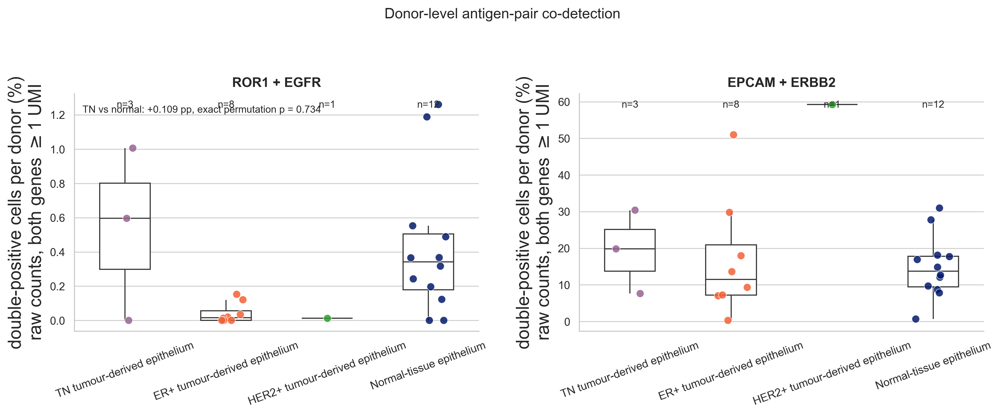

In [88]:
fig, axes = plt.subplots(1, len(antigen_pairs), figsize=(13, 5.2), sharey=False)

for ax, (gene_a, gene_b) in zip(np.atleast_1d(axes), antigen_pairs):

    pair = f"{gene_a}+{gene_b}"
    block = donor_levels[(donor_levels["pair"] == pair) & (donor_levels["min_umi"] == primary_min_umi)]
    present = [g for g in group_order if g in set(block["group"])]

    sns.boxplot(data=block, x="group", y="prevalence", order=present, ax=ax,
                showfliers=False, width=0.5, boxprops={"facecolor": "white"}, showcaps=False)
    sns.stripplot(data=block, x="group", y="prevalence", order=present, ax=ax,
                  hue="group", palette=group_palette, legend=False,
                  size=7, alpha=0.85, jitter=0.18, linewidth=0.5, edgecolor="white")

    for position, group in enumerate(present):
        donors = block.loc[block["group"] == group]
        ax.text(position, ax.get_ylim()[1] * 0.97, f"n={len(donors)}",
                ha="center", va="top", fontsize=9)

    ax.set_title(f"{gene_a} + {gene_b}", fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(f"double-positive cells per donor (%)\nraw counts, both genes $\\geq${primary_min_umi} UMI")
    ax.tick_params(axis="x", rotation=20)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].annotate(
    f"TN vs normal: {donor_inference['difference_pp']:+.3f} pp, "
    f"exact permutation p = {donor_inference['exact_permutation_p']:.3f}",
    xy=(0.02, 0.92), xycoords="axes fraction", fontsize=9,
)

fig.suptitle("Donor-level antigen-pair co-detection", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(fig_dir / "fig2b_donor_level_codetection.png", dpi=300, bbox_inches="tight")
plt.show()


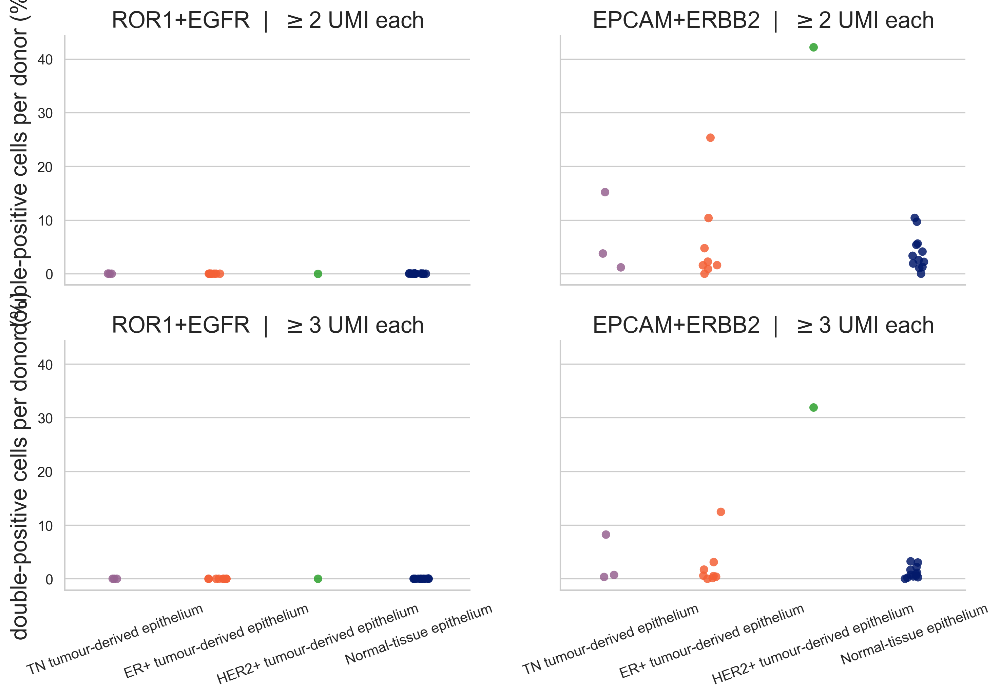

In [89]:
# the stricter thresholds belong in the supplement, not the main panel
supplementary = donor_levels[donor_levels["min_umi"] > primary_min_umi]

g = sns.catplot(data=supplementary, x="group", y="prevalence", col="pair", row="min_umi",
                order=[g for g in group_order if g in set(supplementary["group"])],
                hue="group", palette=group_palette, legend=False,
                kind="strip", height=3.4, aspect=1.5, size=6, alpha=0.85)

g.set_axis_labels("", "double-positive cells per donor (%)")
g.set_titles("{col_name}  |  $\\geq${row_name} UMI each")


for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=20)


g.figure.savefig(fig_dir / "fig2b_supplement_umi_thresholds.png", dpi=300, bbox_inches="tight")
plt.show()


In [90]:
def exact_difference_in_means(first, second):
    """Two-sided exact label permutation for a difference in donor means."""
    first = np.asarray(first, dtype=float)
    second = np.asarray(second, dtype=float)
    observed = first.mean() - second.mean()
    pooled = np.concatenate([first, second])
    indices = np.arange(len(pooled))

    null = np.array([
        pooled[list(group)].mean()
        - pooled[np.setdiff1d(indices, group, assume_unique=True)].mean()
        for group in combinations(indices, len(first))
    ])
    p_value = np.mean(np.abs(null) >= abs(observed) - 1e-12)
    return observed, float(p_value), int(len(null))


## Programme composition of co-detected cells

Programme counts are descriptive cell-level summaries. The donor-level
prevalence figure above and the conditional tests below carry the inference.

In [91]:
hallmark_order = list(epi.uns["meta_programme_hallmark_order"])

hallmark_palette = dict(zip(hallmark_order, epi.uns["meta_programme_hallmark_colors"]))

# Uncertain and unscored cells remain explicit so every stacked bar includes
# all co-expressing cells in its denominator.
non_programme = [
    "low_activity",
    "mixed_active_but_ambiguous",
    "not_scored",
    "normal_tissue",
]


In [92]:
hallmark_palette.update({
    "low_activity": "#BDBDBD",
    "mixed_active_but_ambiguous": "#4D4D4D",
    "not_scored": "#D9D9D9",
    "normal_tissue": "#F0F0F0",
})

# Activity-supported meta-programme assignment from 003b. This includes
# explicit low-activity and ambiguous categories rather than forcing every cell
# into the class with the largest relative score.
state_key = "MP_programme_call"


In [93]:
observed_states = set(epi.obs[state_key].astype(str))

states = [s for s in hallmark_order + non_programme if s in observed_states]

# The shared condition palette is defined near the first condition-level plot.
assert set(condition_palette) == {"N", "ER+", "HER2+", "TN"}

panel_conditions = ["TN", "ER+", "HER2+", "N"]


In [94]:
def coexpression_composition(double_positive, scope_mask=None, conditions=None):
    # per condition: total co-expressing cells, their programme classes, and the percentage of that condition which co-expresses
    counts = {}
    totals = {}
    percentages = {}

    if scope_mask is None:
        scope_mask = np.ones(epi.n_obs, bool)

    if conditions is None:
        conditions = panel_conditions

    state_values = epi.obs[state_key].astype(str).to_numpy()
    condition_values = epi.obs["condition"].astype(str).to_numpy()

    for condition in conditions:

        condition_mask = (condition_values == condition) & scope_mask
        both = condition_mask & double_positive

        totals[condition] = int(both.sum())
        percentages[condition] = 100 * both.sum() / condition_mask.sum()
        counts[condition] = {s: int((both & (state_values == s)).sum()) for s in states}

    return counts, totals, percentages


In [95]:
def coexpression_state_table(min_umi, scope):
    """Return cell-level programme counts without treating cells as replicates."""
    if scope == "all_epithelial":
        scope_mask = np.ones(epi.n_obs, dtype=bool)
        conditions_in_scope = panel_conditions
    elif scope == "tumour_derived":
        scope_mask = tumour_derived_only
        conditions_in_scope = [
            condition for condition in panel_conditions if condition != "N"
        ]
    elif scope == "tumour_derived_cnv_high":
        scope_mask = tumour_derived_cnv_high_only
        conditions_in_scope = [
            condition for condition in panel_conditions if condition != "N"
        ]
    elif scope == "tumour_derived_cnv_high_g1":
        scope_mask = tumour_derived_cnv_high_g1_only
        conditions_in_scope = [
            condition for condition in panel_conditions if condition != "N"
        ]
    else:
        raise ValueError(f"Unknown scope: {scope}")

    rows = []
    condition_values = epi.obs["condition"].astype(str).to_numpy()

    for gene_a, gene_b in antigen_pairs:
        double_positive = np.asarray(
            coexpression_group(epi, gene_a, gene_b, min_umi) == "Double positive"
        )
        counts, totals, percentages = coexpression_composition(
            double_positive, scope_mask, conditions_in_scope
        )

        for condition in conditions_in_scope:
            condition_mask = scope_mask & (condition_values == condition)
            rows.append({
                "pair": f"{gene_a}+{gene_b}",
                "scope": scope,
                "min_umi": min_umi,
                "condition": condition,
                "n_cells_in_scope": int(condition_mask.sum()),
                "n_double_positive": totals[condition],
                "pct_of_condition": percentages[condition],
                **{f"n_{state}": counts[condition][state] for state in states},
            })

    return pd.DataFrame(rows)


In [96]:
coexpression_panel_values = pd.concat(
    [
        coexpression_state_table(threshold, scope)
        for threshold in min_umi_sweep
        for scope in [
            "all_epithelial", "tumour_derived", "tumour_derived_cnv_high",
            "tumour_derived_cnv_high_g1",
        ]
    ],
    ignore_index=True,
)

coexpression_panel_values.to_csv(
    df_dir / "coexpression_panel_values.csv", index=False
)


In [97]:
assert (
    coexpression_panel_values.filter(like="n_").filter(regex="^n_(?!cells|double)").sum(axis=1)
    == coexpression_panel_values["n_double_positive"]
).all()

display(coexpression_panel_values[[
    "pair", "scope", "min_umi", "condition",
    "n_cells_in_scope", "n_double_positive", "pct_of_condition",
]].round(4))


,pair,scope,min_umi,condition,n_cells_in_scope,n_double_positive,pct_of_condition
0,ROR1+EGFR,all_epithelial,1,TN,26904,214,0.7954
1,ROR1+EGFR,all_epithelial,1,ER+,59992,19,0.0317
2,ROR1+EGFR,all_epithelial,1,HER2+,16533,2,0.0121
3,ROR1+EGFR,all_epithelial,1,N,25682,113,0.4400
4,EPCAM+ERBB2,all_epithelial,1,TN,26904,3707,13.7786
...,...,...,...,...,...,...,...
73,ROR1+EGFR,tumour_derived_cnv_high_g1,3,ER+,5629,0,0.0000
74,ROR1+EGFR,tumour_derived_cnv_high_g1,3,HER2+,2519,0,0.0000
75,EPCAM+ERBB2,tumour_derived_cnv_high_g1,3,TN,2871,22,0.7663
76,EPCAM+ERBB2,tumour_derived_cnv_high_g1,3,ER+,5629,205,3.6419


### Is the cell-cycle plurality an enrichment?

Cell Cycle being the largest class among double positives is a statement about their composition, not about enrichment. The primary population-level comparison below is restricted to TN tumour-derived epithelium and pairs each donor's double-positive cells with the remaining programme-scored tumour-derived epithelial cells from that donor. A secondary CMH analysis estimates the cell-level association conditional on the observed donors; it is reported separately because cells do not replace donors as biological replicates.


In [98]:
tn_tumour_derived = (
    tumour_derived_only & (condition_values == "TN")
)

state_values = epi.obs[state_key].astype(str).to_numpy()

# Only cells with a programme call contribute to programme fractions.
programme_scored = ~np.isin(state_values, ["normal_tissue", "not_scored"])


In [99]:
ror1_egfr_double_positive = (
    (raw_counts(epi, "ROR1") >= primary_min_umi)
    & (raw_counts(epi, "EGFR") >= primary_min_umi)
)

tn_scored_tumour_derived = (
    tumour_derived_only
    & (condition_values == "TN")
    & programme_scored
)

rows = []


In [100]:
for donor in np.unique(patient_values[tn_scored_tumour_derived]):

    in_donor = tn_scored_tumour_derived & (patient_values == donor)

    positive = in_donor & ror1_egfr_double_positive
    remainder = in_donor & ~ror1_egfr_double_positive

    # computed for every donor; the eligibility rule is applied per analysis below
    rows.append({
        "donor": donor,
        "n_double_positive": int(positive.sum()),
        "n_other_tumour": int(remainder.sum()),
        "cell_cycle_in_double_positive": (
            100 * (state_values[positive] == "Cell Cycle").mean() if positive.sum() else np.nan
        ),
        "cell_cycle_in_other": (
            100 * (state_values[remainder] == "Cell Cycle").mean() if remainder.sum() else np.nan
        ),
    })


In [101]:
cell_cycle_by_donor = pd.DataFrame(rows)
cell_cycle_by_donor["difference_pp"] = (
    cell_cycle_by_donor["cell_cycle_in_double_positive"] - cell_cycle_by_donor["cell_cycle_in_other"]
)

cell_cycle_by_donor["eligible"] = cell_cycle_by_donor["n_double_positive"] >= min_double_positive_cells

cell_cycle_by_donor.to_csv(df_dir / "coexpression_cell_cycle_by_donor.csv", index=False)

display(cell_cycle_by_donor.round(1))


,donor,n_double_positive,n_other_tumour,cell_cycle_in_double_positive,cell_cycle_in_other,difference_pp,eligible
0,TN,79,13289,60.8,44.8,16.0,True
1,TN-B1,134,13186,44.0,20.1,24.0,True
2,TN-MH0114,0,158,NaN,4.4,NaN,False


In [102]:
# a zero paired difference carries no directional information, so the sign test is taken over the donors whose difference is non-zero
paired = cell_cycle_by_donor.loc[cell_cycle_by_donor["eligible"], "difference_pp"].dropna().to_numpy()
nonzero = paired[paired != 0]


In [103]:
cell_cycle_enrichment = {
    "donors_examined": int(len(cell_cycle_by_donor)),
    "min_double_positive_cells": int(min_double_positive_cells),
    "eligible_donors": int(len(paired)),
    "donors_positive": int((paired > 0).sum()),
    "donors_negative": int((paired < 0).sum()),
    "donors_tied": int((paired == 0).sum()),
    "sign_test_denominator": int(len(nonzero)),
    "median_difference_pp": float(np.median(paired)) if len(paired) else np.nan,
    "sign_test_p": float(binomtest(int((nonzero > 0).sum()), len(nonzero)).pvalue) if len(nonzero) else np.nan,
    "smallest_attainable_p": float(binomtest(len(nonzero), len(nonzero)).pvalue) if len(nonzero) else np.nan,
}


In [104]:
epi.uns["coexpression_cell_cycle"] = cell_cycle_enrichment

display(cell_cycle_enrichment)


{'donors_examined': 3,
 'min_double_positive_cells': 5,
 'eligible_donors': 2,
 'donors_positive': 2,
 'donors_negative': 0,
 'donors_tied': 0,
 'sign_test_denominator': 2,
 'median_difference_pp': 19.989446351638385,
 'sign_test_p': 0.5,
 'smallest_attainable_p': 0.5}

In [105]:
# how much does the eligibility threshold decide the answer?
rows = []


In [106]:
for threshold in [1, 5, 10, 20]:

    difference = cell_cycle_by_donor.loc[
        cell_cycle_by_donor["n_double_positive"] >= threshold, "difference_pp"
    ].dropna()

    nonzero = difference[difference != 0]

    rows.append({
        "min_double_positive_cells": threshold,
        "eligible_donors": len(difference),
        "donors_positive": int((difference > 0).sum()),
        "donors_negative": int((difference < 0).sum()),
        "donors_tied": int((difference == 0).sum()),
        "sign_test_denominator": len(nonzero),
        "median_difference_pp": difference.median() if len(difference) else np.nan,
        "sign_test_p": binomtest(int((nonzero > 0).sum()), len(nonzero)).pvalue if len(nonzero) else np.nan,
        "smallest_attainable_p": binomtest(len(nonzero), len(nonzero)).pvalue if len(nonzero) else np.nan,
    })


In [107]:
eligibility_sweep = pd.DataFrame(rows)

eligibility_sweep.to_csv(df_dir / "coexpression_cell_cycle_eligibility_sweep.csv", index=False)

display(eligibility_sweep.round(3))


,min_double_positive_cells,eligible_donors,donors_positive,donors_negative,donors_tied,sign_test_denominator,median_difference_pp,sign_test_p,smallest_attainable_p
0,1,2,2,0,0,2,19.989,0.5,0.5
1,5,2,2,0,0,2,19.989,0.5,0.5
2,10,2,2,0,0,2,19.989,0.5,0.5
3,20,2,2,0,0,2,19.989,0.5,0.5


### Conditional cell-level programme association


The donor sign test above is the primary test of generalisation across tumours.
The CMH analysis asks a narrower question: within the eligible TN tumours, are
double-positive cells more likely than the remaining tumour-derived epithelial cells to carry
each of the 13 biological programme classes? Low-activity and ambiguous cells
remain in the reference denominator but are not treated as additional
biological hypotheses. Holm correction is applied across all 13 classes. A
class absent from the analysed TN cells is retained with p = 1 and an undefined
odds ratio rather than being removed from the testing family.

This is conditional cell-level evidence within the observed donors, not a
substitute for donor-level replication. Library-depth stratification is
reported separately as a sensitivity analysis.


In [108]:
sample_values = epi.obs["sample"].astype(str).to_numpy()
patient_values = epi.obs["patient"].astype(str).to_numpy()
eligible_programme_donors = set(
    cell_cycle_by_donor.loc[cell_cycle_by_donor["eligible"], "donor"].astype(str)
)

observed_programmes = set(state_values[tn_scored_tumour_derived])
missing_programmes = [
    programme for programme in hallmark_order
    if programme not in observed_programmes
]


In [109]:
# Uncertainty states remain part of the comparison denominator, but only the
# 13 biological classes are separate hypotheses.
programmes = list(hallmark_order)
programme_rows = []


In [110]:
for programme in programmes:
    tables = []

    for donor in sorted(eligible_programme_donors):
        in_donor = tn_scored_tumour_derived & (patient_values == donor)
        positive = in_donor & ror1_egfr_double_positive
        remainder = in_donor & ~ror1_egfr_double_positive

        table = np.array([
            [int((state_values[positive] == programme).sum()),
             int((state_values[positive] != programme).sum())],
            [int((state_values[remainder] == programme).sum()),
             int((state_values[remainder] != programme).sum())],
        ])

        assert table.sum(axis=1).min() > 0
        tables.append(table)

    stacked = np.dstack(tables)
    pooled = stacked.sum(axis=2)
    n_programme_double_positive = int(pooled[0, 0])
    n_programme_remainder = int(pooled[1, 0])
    n_programme_total = n_programme_double_positive + n_programme_remainder
    n_cells_total = int(pooled.sum())

    testable = 0 < n_programme_total < n_cells_total
    common_odds_ratio = np.nan
    ci_low = np.nan
    ci_high = np.nan
    p_cmh = 1.0
    reason = "programme absent" if n_programme_total == 0 else "no outcome variation"

    if testable:
        fit = StratifiedTable(stacked)
        common_odds_ratio = float(fit.oddsratio_pooled)
        p_cmh = float(fit.test_null_odds().pvalue)
        reason = "tested"

        if np.isfinite(common_odds_ratio) and common_odds_ratio > 0:
            ci_low, ci_high = map(float, fit.oddsratio_pooled_confint())

        if not np.isfinite(p_cmh):
            p_cmh = 1.0
            testable = False
            reason = "no informative CMH contrast"

    programme_rows.append({
        "programme": programme,
        "eligible_donors": len(tables),
        "min_double_positive_cells": min_double_positive_cells,
        "n_programme_double_positive": n_programme_double_positive,
        "n_programme_remainder": n_programme_remainder,
        "testable": bool(testable),
        "status": reason,
        "common_odds_ratio": common_odds_ratio,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_cmh": p_cmh,
    })


In [111]:
programme_cmh = pd.DataFrame(programme_rows).sort_values("p_cmh").reset_index(drop=True)

assert programme_cmh["programme"].is_unique
assert set(programme_cmh["programme"]) == set(hallmark_order)

programme_cmh["p_holm"] = multipletests(
    programme_cmh["p_cmh"], method="holm"
)[1]
programme_cmh.to_csv(df_dir / "coexpression_programme_cmh.csv", index=False)
display(programme_cmh.round(4))


,programme,eligible_donors,min_double_positive_cells,n_programme_double_positive,n_programme_remainder,testable,status,common_odds_ratio,ci_low,ci_high,p_cmh,p_holm
0,Cell Cycle,2,5,107,8592,True,tested,2.5468,1.9279,3.3644,0.0000,0.0000
1,Stress or Hypoxia,2,5,17,1298,True,tested,1.7952,1.0897,2.9573,0.0196,0.2351
2,Neural Lineage,2,5,0,503,True,tested,0.0000,NaN,NaN,0.0492,0.5414
3,Other Lineage,2,5,0,320,True,tested,0.0000,NaN,NaN,0.1606,1.0000
4,Secreted,2,5,7,543,True,tested,1.6568,0.7760,3.5374,0.1875,1.0000
5,Interferon and MHC II,2,5,4,756,True,tested,0.5453,0.2012,1.4774,0.2268,1.0000
6,Protein Regulation,2,5,3,214,True,tested,1.7961,0.5693,5.6665,0.3113,1.0000
7,Mesenchymal,2,5,13,1295,True,tested,1.2742,0.7249,2.2396,0.3986,1.0000
8,Oncogenic,2,5,0,52,True,tested,0.0000,NaN,NaN,0.4812,1.0000
9,Senescence,2,5,16,3025,True,tested,0.8475,0.4899,1.4660,0.5551,1.0000


In [112]:
# Non-parametric depth adjustment: split cells into library-size quantiles within each technical sample, then stratify jointly by patient, sample and depth bin. This preserves the biological donor key without mixing libraries.
depth_frame = pd.DataFrame({
    "patient": patient_values[tn_scored_tumour_derived],
    "sample": sample_values[tn_scored_tumour_derived],
    "double_positive": ror1_egfr_double_positive[tn_scored_tumour_derived],
    "cell_cycle": state_values[tn_scored_tumour_derived] == "Cell Cycle",
    "log_library_size": np.log1p(
        epi.obs["total_counts"].to_numpy()[tn_scored_tumour_derived]
    ),
})
depth_frame = depth_frame[depth_frame["patient"].isin(eligible_programme_donors)].copy()

depth_rows = []


In [113]:
for n_bins in [5, 10, 20]:
    tables = []

    for (patient, sample), donor_frame in depth_frame.groupby(["patient", "sample"], observed=True):
        donor_frame = donor_frame.copy()
        donor_frame["depth_bin"] = pd.qcut(
            donor_frame["log_library_size"], q=n_bins, labels=False, duplicates="drop"
        )

        for _, block in donor_frame.groupby("depth_bin", observed=True):
            if block["double_positive"].nunique() < 2 or block["cell_cycle"].nunique() < 2:
                continue

            table = (pd.crosstab(block["double_positive"], block["cell_cycle"])
                     .reindex(index=[True, False], columns=[True, False], fill_value=0)
                     .to_numpy())
            tables.append(table)

    fit = StratifiedTable(np.dstack(tables))
    ci_low, ci_high = fit.oddsratio_pooled_confint()

    depth_rows.append({
        "depth_bins_per_donor": n_bins,
        "informative_strata": len(tables),
        "eligible_donors": len(eligible_programme_donors),
        "common_odds_ratio": float(fit.oddsratio_pooled),
        "ci_low": float(ci_low),
        "ci_high": float(ci_high),
        "p_cmh": float(fit.test_null_odds().pvalue),
    })


In [114]:
cell_cycle_depth_sensitivity = pd.DataFrame(depth_rows)
cell_cycle_depth_sensitivity.to_csv(
    df_dir / "coexpression_cell_cycle_depth_sensitivity.csv", index=False
)

cell_cycle_row = programme_cmh.loc[programme_cmh["programme"] == "Cell Cycle"].iloc[0]


In [115]:
epi.uns["coexpression_cell_cycle"].update({
    "conditional_cell_level_cmh_or": float(cell_cycle_row["common_odds_ratio"]),
    "conditional_cell_level_cmh_ci": [float(cell_cycle_row["ci_low"]), float(cell_cycle_row["ci_high"])],
    "conditional_cell_level_cmh_p": float(cell_cycle_row["p_cmh"]),
    "conditional_cell_level_cmh_holm_p": float(cell_cycle_row["p_holm"]),
    "depth_sensitivity": {
        str(int(row["depth_bins_per_donor"])): {
            key: (int(value) if key in ["informative_strata", "eligible_donors"] else float(value))
            for key, value in row.items() if key != "depth_bins_per_donor"
        }
        for row in depth_rows
    },
})


In [116]:
display(cell_cycle_row.to_frame().T.round(4), cell_cycle_depth_sensitivity.round(4))


,programme,eligible_donors,min_double_positive_cells,n_programme_double_positive,n_programme_remainder,testable,status,common_odds_ratio,ci_low,ci_high,p_cmh,p_holm
0,Cell Cycle,2,5,107,8592,True,tested,2.546836,1.927922,3.364437,0.0,0.0


,depth_bins_per_donor,informative_strata,eligible_donors,common_odds_ratio,ci_low,ci_high,p_cmh
0,5,18,2,1.1232,0.8399,1.5022,0.4326
1,10,33,2,1.0827,0.8075,1.4517,0.5959
2,20,55,2,1.0858,0.8103,1.4551,0.5800


In [117]:
# Does EGFR add a pair-specific difference among cells where ROR1 is detected?
conditional_donors = eligible_donors[
    eligible_donors["group"].isin(["TN tumour-derived epithelium", "Normal-tissue epithelium"])
].copy()
conditional_donors["egfr_given_ror1_pct"] = np.where(
    conditional_donors["n_ror1"] > 0,
    100 * conditional_donors["n_double_positive"] / conditional_donors["n_ror1"],
    np.nan,
)

conditional_rows = []


In [118]:
for min_ror1_cells in [1, 5, 10]:
    eligible = conditional_donors[conditional_donors["n_ror1"] >= min_ror1_cells]
    tn = eligible.loc[
        eligible["group"] == "TN tumour-derived epithelium", "egfr_given_ror1_pct"
    ].to_numpy()
    normal_values = eligible.loc[
        eligible["group"] == "Normal-tissue epithelium", "egfr_given_ror1_pct"
    ].to_numpy()

    if len(tn) >= 2 and len(normal_values) >= 2:
        difference, p_value, n_permutations = exact_difference_in_means(
            tn, normal_values
        )
    else:
        difference, p_value, n_permutations = np.nan, np.nan, 0

    conditional_rows.append({
        "min_ror1_positive_cells": min_ror1_cells,
        "tn_donors": len(tn),
        "normal_donors": len(normal_values),
        "tn_mean_pct": tn.mean() if len(tn) else np.nan,
        "normal_mean_pct": normal_values.mean() if len(normal_values) else np.nan,
        "difference_pp": difference,
        "exact_permutation_p": p_value,
        "n_permutations": n_permutations,
    })


In [119]:
conditional_pair_sensitivity = pd.DataFrame(conditional_rows)
conditional_pair_sensitivity["p_holm"] = multipletests(
    conditional_pair_sensitivity["exact_permutation_p"], method="holm"
)[1]

conditional_donors.to_csv(
    df_dir / "egfr_detection_given_ror1_by_donor.csv", index=False
)
conditional_pair_sensitivity.to_csv(
    df_dir / "egfr_detection_given_ror1_sensitivity.csv", index=False
)


In [120]:
display(conditional_pair_sensitivity.round(4))


,min_ror1_positive_cells,tn_donors,normal_donors,tn_mean_pct,normal_mean_pct,difference_pp,exact_permutation_p,n_permutations,p_holm
0,1,3,11,16.8281,48.1985,-31.3704,0.0357,364,0.1071
1,5,2,8,25.2421,53.7729,-28.5308,0.0667,45,0.1111
2,10,2,7,25.2421,51.9309,-26.6888,0.0556,36,0.1111


In [121]:
# Leave each TN donor out in turn. This diagnoses dependence on one tumour;
# it is not a family of independent confirmatory tests.
primary_donors = eligible_donors[
    eligible_donors["group"].isin(["TN tumour-derived epithelium", "Normal-tissue epithelium"])
].copy()
normal_values = primary_donors.loc[
    primary_donors["group"] == "Normal-tissue epithelium", "prevalence"
].to_numpy()

loo_rows = []
tn_block = primary_donors[primary_donors["group"] == "TN tumour-derived epithelium"]


In [122]:
for omitted in [None, *tn_block["patient"].astype(str)]:
    retained = tn_block if omitted is None else tn_block[tn_block["patient"] != omitted]
    difference, p_value, n_permutations = exact_difference_in_means(
        retained["prevalence"].to_numpy(), normal_values
    )
    loo_rows.append({
        "omitted_tn_donor": "none" if omitted is None else omitted,
        "tn_donors": len(retained),
        "normal_donors": len(normal_values),
        "difference_pp": difference,
        "exact_permutation_p": p_value,
        "n_permutations": n_permutations,
    })


In [123]:
leave_one_tn_out = pd.DataFrame(loo_rows)


In [124]:
tn_concentration = tn_block[[
    "patient", "n_cells", "n_ror1", "n_egfr", "n_double_positive", "prevalence",
]].copy()
tn_concentration["share_of_tn_double_positive_pct"] = (
    100 * tn_concentration["n_double_positive"]
    / tn_concentration["n_double_positive"].sum()
)
tn_concentration = tn_concentration.sort_values(
    "n_double_positive", ascending=False
)


In [125]:
leave_one_tn_out.to_csv(
    df_dir / "ror1_egfr_leave_one_tn_donor_out.csv", index=False
)
tn_concentration.to_csv(
    df_dir / "ror1_egfr_tn_donor_concentration.csv", index=False
)

display(leave_one_tn_out.round(4))
display(tn_concentration.round(3))


,omitted_tn_donor,tn_donors,normal_donors,difference_pp,exact_permutation_p,n_permutations
0,none,3,12,0.1089,0.7341,455
1,TN,2,12,0.0780,0.9121,91
2,TN-B1,2,12,-0.1271,0.7473,91
3,TN-MH0114,2,12,0.3759,0.2088,91


,patient,n_cells,n_ror1,n_egfr,n_double_positive,prevalence,share_of_tn_double_positive_pct
22,TN-B1,13320,515,1524,134,1.006,62.617
21,TN,13426,327,2717,80,0.596,37.383
23,TN-MH0114,158,1,48,0,0.000,0.000


## Detected-gene sensitivity

The primary QC pipeline does not impose a universal 500-gene threshold because
sample-adaptive QC was used. This sensitivity table checks whether excluding
cells with fewer than 500 detected genes changes the antigen conclusions.

In [126]:
gene_complexity = epi.obs["n_genes_by_counts"].to_numpy()
condition_values = epi.obs["condition"].astype(str).to_numpy()
ror1_count = raw_counts(epi, "ROR1")
egfr_count = raw_counts(epi, "EGFR")
double_positive = (ror1_count >= primary_min_umi) & (egfr_count >= primary_min_umi)

complexity_rows = []


In [127]:
for condition in conditions:
    in_condition = condition_values == condition

    for minimum_genes in [0, 500]:
        retained = in_condition & (gene_complexity >= minimum_genes)
        ror1_positive = retained & (ror1_count >= primary_min_umi)

        complexity_rows.append({
            "condition": condition,
            "minimum_detected_genes": minimum_genes,
            "n_cells": int(retained.sum()),
            "n_ror1_positive": int(ror1_positive.sum()),
            "n_double_positive": int((retained & double_positive).sum()),
            "double_positive_pct": 100 * double_positive[retained].mean(),
            "egfr_given_ror1_pct": (
                100 * (ror1_positive & (egfr_count >= primary_min_umi)).sum()
                / ror1_positive.sum()
                if ror1_positive.sum() else np.nan
            ),
        })


In [128]:
complexity_sensitivity = pd.DataFrame(complexity_rows)
complexity_sensitivity.to_csv(
    df_dir / "antigen_min_genes_sensitivity.csv", index=False
)

low_complexity_double_positive = pd.DataFrame([{
    "cells_below_500_genes": int((gene_complexity < 500).sum()),
    "double_positive_below_500_genes": int(
        ((gene_complexity < 500) & double_positive).sum()
    ),
}])


In [129]:
low_complexity_double_positive.to_csv(
    df_dir / "antigen_low_complexity_double_positive.csv", index=False
)

display(complexity_sensitivity.round(4))
display(low_complexity_double_positive)


,condition,minimum_detected_genes,n_cells,n_ror1_positive,n_double_positive,double_positive_pct,egfr_given_ror1_pct
0,N,0,25682,213,113,0.4400,53.0516
1,N,500,23968,211,113,0.4715,53.5545
2,ER+,0,59992,98,19,0.0317,19.3878
3,ER+,500,50968,94,19,0.0373,20.2128
4,HER2+,0,16533,17,2,0.0121,11.7647
5,HER2+,500,15036,17,2,0.0133,11.7647
6,TN,0,26904,843,214,0.7954,25.3855
7,TN,500,25441,841,214,0.8412,25.4459


,cells_below_500_genes,double_positive_below_500_genes
0,13698,0


## Save

Retained-doublet-score sensitivity. Exclude cells above the within-sample singlet score q95 or q90; retain the same raw-count thresholds and donor eligibility. Scores are not calibrated across samples. Programme calls are held fixed after filtering; this is not a new scoring run or ambient-RNA correction.

In [130]:
import sys
repository = find_publication()
if str(repository) not in sys.path:
    sys.path.insert(0, str(repository))
check_dir = repository / "results" / "publication_checks"
check_dir.mkdir(parents=True, exist_ok=True)

from scripts.publication_targeted_checks import doublet_sensitivity

doublet_prevalence, doublet_programmes = doublet_sensitivity(epi, check_dir)
display(doublet_prevalence)
display(doublet_programmes)


,retained_score_quantile,min_umi,tn_donors,normal_donors,difference_pp,exact_permutation_p,n_permutations
0,1.00,1,3,12,0.108902,0.734066,455
1,1.00,2,3,12,-0.005106,0.857143,455
2,0.95,1,3,12,0.110218,0.778022,455
3,0.95,2,3,12,-0.005375,0.857143,455
4,0.90,1,3,12,0.123985,0.683516,455
5,0.90,2,3,12,-0.008455,0.854945,455


,retained_score_quantile,n_units,r_squared,p_permutation
0,1.00,12,NaN,NaN
1,0.95,12,NaN,NaN
2,0.90,12,NaN,NaN


In [131]:
assert not epi.uns.get("figure_only", False), "Plotting-only object: do not run analysis save cells."

final_positive = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}

assert final_positive == baseline_positive

out_path = save_dir / "epithelial_antigen_coexpression.h5ad"

tmp_path = out_path.with_suffix(".h5ad.tmp")

epi.write_h5ad(tmp_path, compression="gzip")


In [132]:
os.replace(tmp_path, out_path)

display(out_path.name)

display(epi)

check = sc.read_h5ad(out_path, backed="r")

assert check.n_obs == epi.n_obs

assert check.n_vars == epi.n_vars


'epithelial_antigen_coexpression.h5ad'

AnnData object with n_obs × n_vars = 129111 × 27356
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'scVI_leiden', 'sample_short', 'celltypist_reference_label', 'celltypist_reference_confidence', 'cl_annotation', 'cnv_score', 'cnv_signal', 'tumour_derived', 'cnv_high', 'tumour_derived_cnv_high', 'g1_cell', 'tumour_derived_cnv_high_g1', 'specimen_origin', 'source_tumour_cluster', 'source_tumour_cluster_eligible', 'source_tumour_cluster_call', 'leiden_r0.5', 'leiden_r1', 'leiden_r1.2', 'leiden_r1.5', 'epi_leiden', 'epi_leiden_protected', 'epi_leiden_seed2', 'analysis_unit', 'MP_dominant_class', 'MP_programme_call', 'MP

In [133]:
del check

gc.collect()


993

In [134]:
from importlib.metadata import PackageNotFoundError, version
import platform
import sys


In [135]:
import session_info

session_info.show()


/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  mod_version = _find_version(mod.__version__)
/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  mod_version = _find_version(mod.__version__)


In [148]:
programme_palette = {
    "Cell Cycle": "#2C7FB8",
    "Stress or Hypoxia": "#A6BDDB",
    "Protein Regulation": "#F28E2B",
    "Mesenchymal": "#FFBE7D",
    "Interferon and MHC II": "#2CA02C",
    "Senescence": "#98DF8A",
    "Oncogenic": "#9467BD",
    "Respiration": "#C5B0D5",
    "Secreted": "#E377C2",
    "Cilia": "#17BECF",
    "Neural Lineage": "#BCBD22",
    "Other Lineage": "#8C564B",
    "Haematological Lineage": "#D62728",
}

In [149]:
meta_programme_hallmarks = {
    "Cell Cycle": ["MP1", "MP2", "MP3", "MP4"],
    "Stress or Hypoxia": ["MP5", "MP6", "MP7"],
    "Protein Regulation": ["MP8", "MP9", "MP10", "MP11"],
    "Mesenchymal": ["MP12", "MP13", "MP14", "MP15", "MP16"],
    "Interferon and MHC II": ["MP17", "MP18"],
    "Senescence": ["MP19"],
    "Oncogenic": ["MP20"],
    "Respiration": ["MP21"],
    "Secreted": ["MP22", "MP23"],
    "Cilia": ["MP24"],
    "Neural Lineage": ["MP25", "MP26", "MP27", "MP28", "MP29"],
    "Other Lineage": ["MP30", "MP31", "MP32"],
    "Haematological Lineage": ["MP33", "MP34", "MP35", "MP36", "MP37"],
    "Unassigned": ["MP38", "MP39", "MP40", "MP41"],
}

In [150]:
notebook_dir = find_publication()

In [151]:
meta_programme_file = notebook_dir / "data" / "cancer_meta_programme_signatures.xlsx"

In [152]:
meta_programme_sheet = pd.read_excel(meta_programme_file, sheet_name="Cancer MPs")
meta_programme_sheet.columns = (
    meta_programme_sheet.columns.astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
)

In [154]:
import re

In [155]:
meta_programme_states = {}
mp_id_to_name = {}
for mp_name in meta_programme_sheet.columns:
    match = re.match(r"^(MP\d+)", mp_name)
    assert match is not None, mp_name

    genes = meta_programme_sheet[mp_name].dropna().astype(str).str.strip()
    genes = genes[genes.ne("")].unique().tolist()
    assert genes, mp_name

    meta_programme_states[mp_name] = genes
    mp_id_to_name[match.group(1)] = mp_name

In [156]:
meta_programme_hallmarks = {
    hallmark: [mp_id_to_name[mp_id] for mp_id in mp_ids if mp_id in mp_id_to_name]
    for hallmark, mp_ids in meta_programme_hallmarks.items()
}
candidate_hallmarks = [name for name in meta_programme_hallmarks if name != "Unassigned"]


In [157]:
point_size = 120_000 / epi.n_obs
plot_values = epi.obs["MP_programme_call"].astype(str)

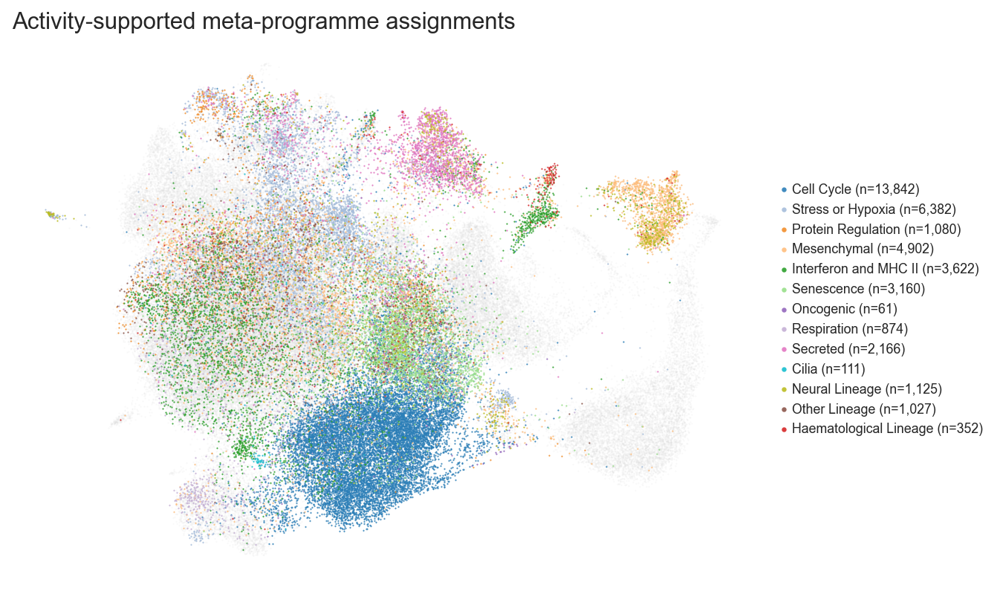

In [158]:
# Draw all epithelial cells first as anatomical context.
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    umap[:, 0],
    umap[:, 1],
    s=point_size,
    color="#D9D9D9",
    alpha=0.18,
    linewidths=0,
    rasterized=True,
)

# Overlay activity-supported assignments after the background.
for programme in candidate_hallmarks:
    mask = (plot_values == programme).to_numpy()
    ax.scatter(
        umap[mask, 0],
        umap[mask, 1],
        s=point_size,
        color=programme_palette[programme],
        alpha=0.9,
        linewidths=0,
        rasterized=True,
        label=f"{programme} (n={mask.sum():,})",
    )

ax.set_title("Activity-supported meta-programme assignments", loc="left")
ax.set_axis_off()
ax.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    frameon=False,
    markerscale=3,
    fontsize=8,
)
fig.savefig(fig_dir / "meta_programme_assignments_umap.svg", bbox_inches="tight")
plt.show()


In [ ]:
#changes for git